# Final Mass
After speaking with Donelan lab, final mass is also an interesting metric - we assume that all oysters started at roughly the same size and then ask what is the final mass/size of the oyster (and smaller oysters tend to grow faster)

So going to look at the final mass of the sequenced oysters (and compare against the full data set)

## 0. load libraries

In [3]:
library(tidyverse)
library(cowplot) # add plots together
library(grid)
library(RColorBrewer)

# for stat testing
library(lme4) # for linear mixed effects model
library(ggpubr)
library(car)
library(rstatix)
library(emmeans) #for post hocs
library(plotrix) #for standard error

set contrasts for statistical analysis

In [4]:
options(contrasts = c("contr.sum","contr.poly")) #could also be contr.treatment for unequal groups sum
getOption("contrasts") 

[1] "contr.sum"  "contr.poly"

## 1. read CSVs

#### metadata
to pull out sequenced oysters

In [5]:
meta <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/metaData/sample_metaData.csv')
head(meta)

,Sample,Phase1_treatment,Phase1_temp,Phase1_DO,Phase1_TankRep,Phase2_treatment,Phase2_temp,Phase2_DO,Phase2_TankRep
,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<int>
1,B1_B1_O01,both,warm,hypoxic,1,both,warm,hypoxic,1
2,B1_Nu_O03,both,warm,hypoxic,1,NA,NA,NA,NA
3,B1_W5_O50,both,warm,hypoxic,1,warm,warm,normoxic,5
4,B2_B5_O51,both,warm,hypoxic,2,both,warm,hypoxic,5
5,B2_C4_O40,both,warm,hypoxic,2,control,ambient,normoxic,4
6,B2_Nu_O12,both,warm,hypoxic,2,NA,NA,NA,NA


#### phase 1

In [6]:
p1.mass <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/metaData/growth_phase1_weights.csv') %>%
# consistent sample naming
mutate(Sample = paste0(substr(Phase_1_treat,1,1), Phase_1_rep, '_Nu_', Tag_color, sprintf("%02d", Tag_num))) %>%
# pull final mass columns and metadata
select(Sample, 'Phase1_treatment' = Phase_1_treat, 'Phase1_temp' = Phase_1_temp, 'Phase1_DO' = Phase_1_DO, 
       Actual_tissue_post_mg, Actual_shell_post_mg) %>%
# add ratio tissue:shell mass column
mutate(Ratio_tissue_shell_mg = Actual_tissue_post_mg / Actual_shell_post_mg)

# pull out only the sequenced oysters
p1.mass <- p1.mass[p1.mass$Sample %in% meta$Sample,]

# set contrasts
p1.mass$Phase1_treatment <- factor(p1.mass$Phase1_treatment, levels = c('Cont', 'Hyp', 'Warm', 'Both'))

colnames(p1.mass)
head(p1.mass)

[1] "Sample"                "Phase1_treatment"      "Phase1_temp"          
[4] "Phase1_DO"             "Actual_tissue_post_mg" "Actual_shell_post_mg" 
[7] "Ratio_tissue_shell_mg"

,Sample,Phase1_treatment,Phase1_temp,Phase1_DO,Actual_tissue_post_mg,Actual_shell_post_mg,Ratio_tissue_shell_mg
,<chr>,<fct>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
3,B1_Nu_O03,Both,Warm,Hyp,60.96492,117.53508,0.5186955
10,B2_Nu_O12,Both,Warm,Hyp,119.78678,192.11322,0.6235218
23,B3_Nu_O24,Both,Warm,Hyp,143.36252,174.53748,0.8213853
31,B4_Nu_O32,Both,Warm,Hyp,171.55326,196.54674,0.8728370
35,B5_Nu_O36,Both,Warm,Hyp,65.18296,84.91704,0.7676075
46,B6_Nu_O47,Both,Warm,Hyp,28.82948,167.57052,0.1720439


#### phase 2

In [7]:
p2.mass <- read.csv('/project/pi_sarah_gignouxwolfsohn_uml_edu/julia/CE_2024/CE24_RNA-seq/metaData/growth_phase2.1_weights.csv') %>%
# consistent sample naming
mutate(Sample = paste0(substr(Phase_1_treat,1,1), Phase_1_rep, '_', substr(Phase_2_treat,1,1), Phase_2_rep, '_', Tag_color, sprintf("%02d", Tag_num))) %>%
# pull final mass columns and metadata
select(Sample, 'Phase1_treatment' = Phase_1_treat, 'Phase1_temp' = Phase_1_temp, 'Phase1_DO' = Phase_1_DO, 
       'Phase2_treatment' = Phase_2_treat, 'Phase2_temp' = Phase_2.1_temp, 'Phase2_DO' = Phase_2.1_DO,
       Actual_tissue_post_mg, Actual_shell_post_mg) %>%
# add ratio tissue:shell mass column
mutate(Ratio_tissue_shell_mg = Actual_tissue_post_mg / Actual_shell_post_mg)

# pull out only the sequenced oysters
p2.mass <- p2.mass[p2.mass$Sample %in% meta$Sample,]

# set contrasts
p2.mass$Phase1_treatment <- factor(p2.mass$Phase1_treatment, levels = c('Cont', 'Hyp', 'Warm', 'Both'))
p2.mass$Phase2_treatment <- factor(p2.mass$Phase2_treatment, levels = c('Cont', 'Hyp', 'Warm', 'Both'))
p2.mass$Phase1_DO <- factor(p2.mass$Phase1_DO, levels = c('Norm', 'Hyp'))
p2.mass$Phase1_temp <- factor(p2.mass$Phase1_temp, levels = c('Ambient', 'Warm'))
p2.mass$Phase2_DO <- factor(p2.mass$Phase2_DO, levels = c('Norm', 'Hyp'))
p2.mass$Phase2_temp <- factor(p2.mass$Phase2_temp, levels = c('Ambient', 'Warm'))


colnames(p2.mass)
head(p2.mass)

[1] "Sample"                "Phase1_treatment"      "Phase1_temp"          
 [4] "Phase1_DO"             "Phase2_treatment"      "Phase2_temp"          
 [7] "Phase2_DO"             "Actual_tissue_post_mg" "Actual_shell_post_mg" 
[10] "Ratio_tissue_shell_mg"

,Sample,Phase1_treatment,Phase1_temp,Phase1_DO,Phase2_treatment,Phase2_temp,Phase2_DO,Actual_tissue_post_mg,Actual_shell_post_mg,Ratio_tissue_shell_mg
,<chr>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>
1,B1_B1_O01,Both,Warm,Hyp,Both,Warm,Hyp,419.7304,541.5696,0.7750258
46,B1_W5_O50,Both,Warm,Hyp,Warm,Warm,Norm,417.8743,883.4257,0.4730159
57,B2_B5_O51,Both,Warm,Hyp,Both,Warm,Hyp,166.1983,313.4017,0.5303046
68,B2_C4_O40,Both,Warm,Hyp,Cont,Ambient,Norm,142.6234,311.9766,0.4571606
103,B3_B4_O41,Both,Warm,Hyp,Both,Warm,Hyp,211.0470,344.7530,0.6121688
114,B3_C3_O30,Both,Warm,Hyp,Cont,Ambient,Norm,480.1150,709.8850,0.6763278


## 2. phase 1 final mass

Sophie's findings from the larger dataset:
- Oysters in hypoxia had significantly less **shell mass** than oysters in normoxia (p < 0.01)
- Oysters in hypoxia tended to have more **tissue:shell** than oysters in normoxia (p = 0.58)
- Oysters in warm environments had significantly more **tissue:shell** than oysters in normoxia (p = 0.02)

### tissue

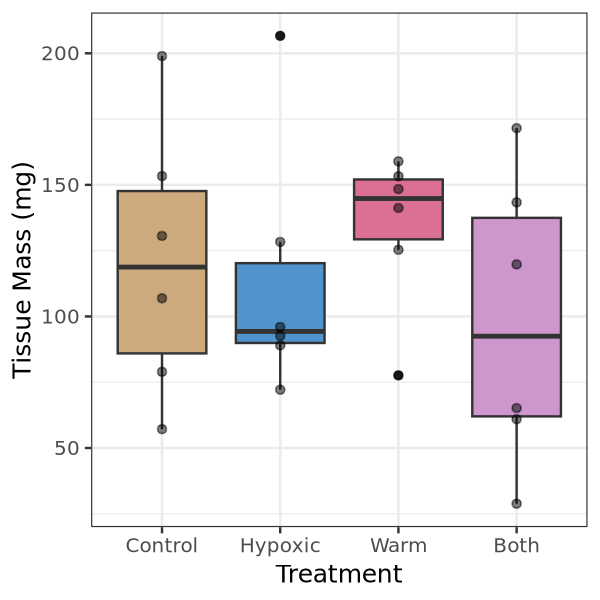

In [8]:
ggplot(p1.mass, aes(x = Phase1_treatment, y = Actual_tissue_post_mg, fill = Phase1_treatment)) +
geom_boxplot() +
geom_point(alpha = 0.5) +
guides(fill = 'none') +
scale_fill_manual(values = c("Hyp" = "steelblue3", "Warm" = "palevioletred", "Cont" = "burlywood3", "Both" = "plum3")) +
    scale_x_discrete(labels = c("Hyp" = "Hypoxic", "Cont" = "Control", "Warm" = "Warm", "Both" = "Both")) +
labs(x = 'Treatment',
     y = 'Tissue Mass (mg)') +
theme_bw(base_size = 15)

oysters that experienced warming have higher average tissue mass than the other treatments 

plotting how Sophie does (mean and SE):

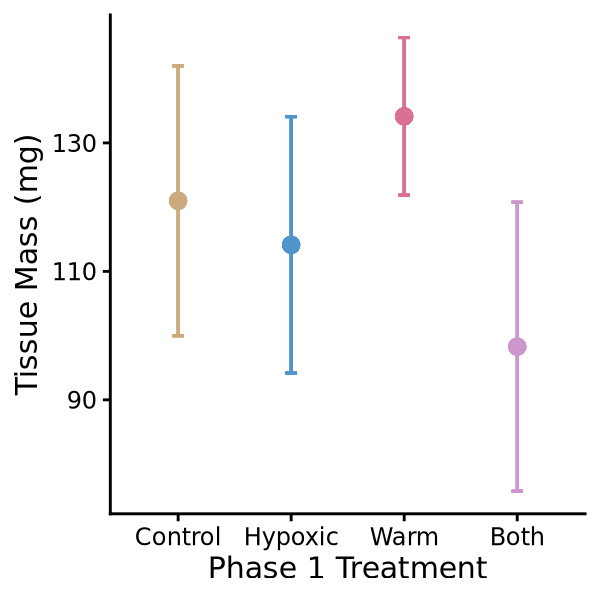

In [9]:
post_summary_stats_t <- p1.mass %>%
  group_by(Phase1_treatment) %>%
  mutate(
    mean_pre = mean(Actual_tissue_post_mg, na.rm = TRUE),
    se_pre = std.error(Actual_tissue_post_mg, na.rm = TRUE))

  #reorder effect of phase 1 Phase_1_treat
  post_summary_stats_t$Phase1_treatment <- factor(post_summary_stats_t$Phase1_treatment,levels = c("Cont", "Hyp","Warm", "Both"))
  
  #plot SHELL
  ggplot(post_summary_stats_t, aes(x = Phase1_treatment, y = mean_pre, color = Phase1_treatment)) +
    geom_point(size = 4, position = position_dodge(0.9)) + # Plot means as points
    geom_errorbar(aes(ymin = mean_pre - se_pre, ymax = mean_pre + se_pre), 
                  width = 0.1, position = position_dodge(0.9)) + # Error bars for SD
    theme_classic(base_size = 18)+
    scale_color_manual(values = c("Hyp" = "steelblue3", "Warm" = "palevioletred", "Cont" = "burlywood3", "Both" = "plum3")) +
    labs(x = "Phase 1 Treatment", y = "Tissue Mass (mg)") +
    scale_x_discrete(labels = c("Hyp" = "Hypoxic", "Cont" = "Control", "Warm" = "Warm", "Both" = "Both")) +
   # ylim(330, 450)+
    theme(legend.position = "none") # Remove legend

#### stat testing:

In [10]:
m1 <- aov(Actual_tissue_post_mg ~ Phase1_DO * Phase1_temp, data = p1.mass)
aov_tab <- Anova(m1, test="F", type="III")

summary(m1)

#remove scientific notation
aov_tab %>%
  mutate(`Pr(>F)` = round(`Pr(>F)`, 4))

                      Df Sum Sq Mean Sq F value Pr(>F)
Phase1_DO              1   2736  2736.3   1.219  0.283
Phase1_temp            1     11    10.9   0.005  0.945
Phase1_DO:Phase1_temp  1   1261  1260.5   0.562  0.462
Residuals             20  44877  2243.9               

,Sum Sq,Df,F value,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>
(Intercept),327862.75286,1,1.461147e+02,0.0000
Phase1_DO,2736.30072,1,1.219454e+00,0.2826
Phase1_temp,10.94083,1,4.875869e-03,0.9450
Phase1_DO:Phase1_temp,1260.53506,1,5.617675e-01,0.4623
Residuals,44877.46456,20,NA,NA


In [11]:
#Tm1, passes the levene test regardless, Q-Q plot looks better when log transformed, same ish results regardless
Tm1 <- lmer(log(Actual_tissue_pre_mg)~ Phase_1_DO*Phase_1_temp +
              (1|Phase_1_rep_R), data = Growth_Data_forR_pre, REML=TRUE)
aov_tab <- Anova(Tm1, test="F", type="III")

#remove scientific notation
aov_tab %>%
  mutate(`Pr(>F)` = round(`Pr(>F)`, 4))

ERROR: Error: bad 'data': object 'Growth_Data_forR_pre' not found


no significant difference of final mass between treatments

diagnostics

In [ ]:
leveneTest((Actual_tissue_post_mg) ~ Phase1_temp * Phase1_DO, p1.mass)
m1.e <- residuals(m1) 
qqnorm(m1.e)
qqline(m1.e)

### shell

In [ ]:
ggplot(p1.mass, aes(x = Phase1_treatment, y = Actual_shell_post_mg, fill = Phase1_treatment)) +
geom_boxplot() +
geom_point(alpha = 0.5) +
guides(fill = 'none') +
scale_fill_manual(values = c("Hyp" = "steelblue3", "Warm" = "palevioletred", "Cont" = "burlywood3", "Both" = "plum3")) +
    scale_x_discrete(labels = c("Hyp" = "Hypoxic", "Cont" = "Control", "Warm" = "Warm", "Both" = "Both")) +
labs(x = 'Treatment',
     y = 'Shell Mass (mg)') +
theme_bw(base_size = 15)

oysters that experienced hypoxia (Hyp and Both) have lower final mass on average than those that experienced normoxia (Cont and Warm)

plotting how Sophie does (mean and SE):

In [ ]:
post_summary_stats_s <- p1.mass %>%
  group_by(Phase1_treatment) %>%
  mutate(
    mean_pre = mean(Actual_shell_post_mg, na.rm = TRUE),
    se_pre = std.error(Actual_shell_post_mg, na.rm = TRUE))

  #reorder effect of phase 1 Phase_1_treat
  post_summary_stats_s$Phase1_treatment <- factor(post_summary_stats_s$Phase1_treatment,levels = c("Cont", "Hyp","Warm", "Both"))
  
  #plot SHELL
  ggplot(post_summary_stats_s, aes(x = Phase1_treatment, y = mean_pre, color = Phase1_treatment)) +
    geom_point(size = 4, position = position_dodge(0.9)) + # Plot means as points
    geom_errorbar(aes(ymin = mean_pre - se_pre, ymax = mean_pre + se_pre), 
                  width = 0.1, position = position_dodge(0.9)) + # Error bars for SD
    theme_classic(base_size = 18)+
    scale_color_manual(values = c("Hyp" = "steelblue3", "Warm" = "palevioletred", "Cont" = "burlywood3", "Both" = "plum3")) +
    labs(x = "Phase 1 Treatment", y = "Shell Mass (mg)") +
    scale_x_discrete(labels = c("Hyp" = "Hypoxic", "Cont" = "Control", "Warm" = "Warm", "Both" = "Both")) +
   # ylim(330, 450)+
    theme(legend.position = "none") # Remove legend

#### stat testing:

In [ ]:
m2 <- aov(Actual_shell_post_mg ~ Phase1_DO*Phase1_temp, data = p1.mass)
aov_tab2 <- Anova(m2, test="F", type="III")

summary(m2)

#remove scientific notation
aov_tab2 %>%
  mutate(`Pr(>F)` = round(`Pr(>F)`, 4))

no significant difference between treatments

diagnostics

In [ ]:
leveneTest((Actual_shell_post_mg) ~ Phase1_temp * Phase1_DO, p1.mass)
m2.e <- residuals(m2) 
qqnorm(m2.e)
qqline(m2.e)

### tissue:shell

In [ ]:
ggplot(p1.mass, aes(x = Phase1_treatment, y = Ratio_tissue_shell_mg, fill = Phase1_treatment)) +
geom_boxplot() +
geom_point(alpha = 0.5) +
guides(fill = 'none') +
scale_fill_manual(values = c("Hyp" = "steelblue3", "Warm" = "palevioletred", "Cont" = "burlywood3", "Both" = "plum3")) +
    scale_x_discrete(labels = c("Hyp" = "Hypoxic", "Cont" = "Control", "Warm" = "Warm", "Both" = "Both")) +
labs(x = 'Treatment',
     y = 'Tissue:Shell Mass (mg)') +
theme_bw(base_size = 15)

more variation in the both oysters than the other treatments

plotting how Sophie does (mean and SE):

In [ ]:
post_summary_stats_r <- p1.mass %>%
  group_by(Phase1_treatment) %>%
  mutate(
    mean_pre = mean(Ratio_tissue_shell_mg, na.rm = TRUE),
    se_pre = std.error(Ratio_tissue_shell_mg, na.rm = TRUE))

  #reorder effect of phase 1 Phase_1_treat
  post_summary_stats_r$Phase1_treatment <- factor(post_summary_stats_r$Phase1_treatment,levels = c("Cont", "Hyp","Warm", "Both"))
  
  #plot SHELL
  ggplot(post_summary_stats_r, aes(x = Phase1_treatment, y = mean_pre, color = Phase1_treatment)) +
    geom_point(size = 4, position = position_dodge(0.9)) + # Plot means as points
    geom_errorbar(aes(ymin = mean_pre - se_pre, ymax = mean_pre + se_pre), 
                  width = 0.1, position = position_dodge(0.9)) + # Error bars for SD
    theme_classic(base_size = 18)+
    scale_color_manual(values = c("Hyp" = "steelblue3", "Warm" = "palevioletred", "Cont" = "burlywood3", "Both" = "plum3")) +
    labs(x = "Phase 1 Treatment", y = "Tissue:Shell Mass (mg)") +
    scale_x_discrete(labels = c("Hyp" = "Hypoxic", "Cont" = "Control", "Warm" = "Warm", "Both" = "Both")) +
   # ylim(330, 450)+
    theme(legend.position = "none") # Remove legend

#### stat testing:

In [ ]:
m3 <- aov(Ratio_tissue_shell_mg ~ Phase1_DO*Phase1_temp, data = p1.mass)
aov_tab3 <- Anova(m3, test="F", type="III")

summary(m3)

#remove scientific notation
aov_tab3 %>%
  mutate(`Pr(>F)` = round(`Pr(>F)`, 4))

no significant difference of final mass between treatments

diagnostics

In [ ]:
leveneTest((Ratio_tissue_shell_mg) ~ Phase1_temp * Phase1_DO, p1.mass)
m3.e <- residuals(m3) 
qqnorm(m3.e)
qqline(m3.e)

## 3. phase 2 final mass

### tissue

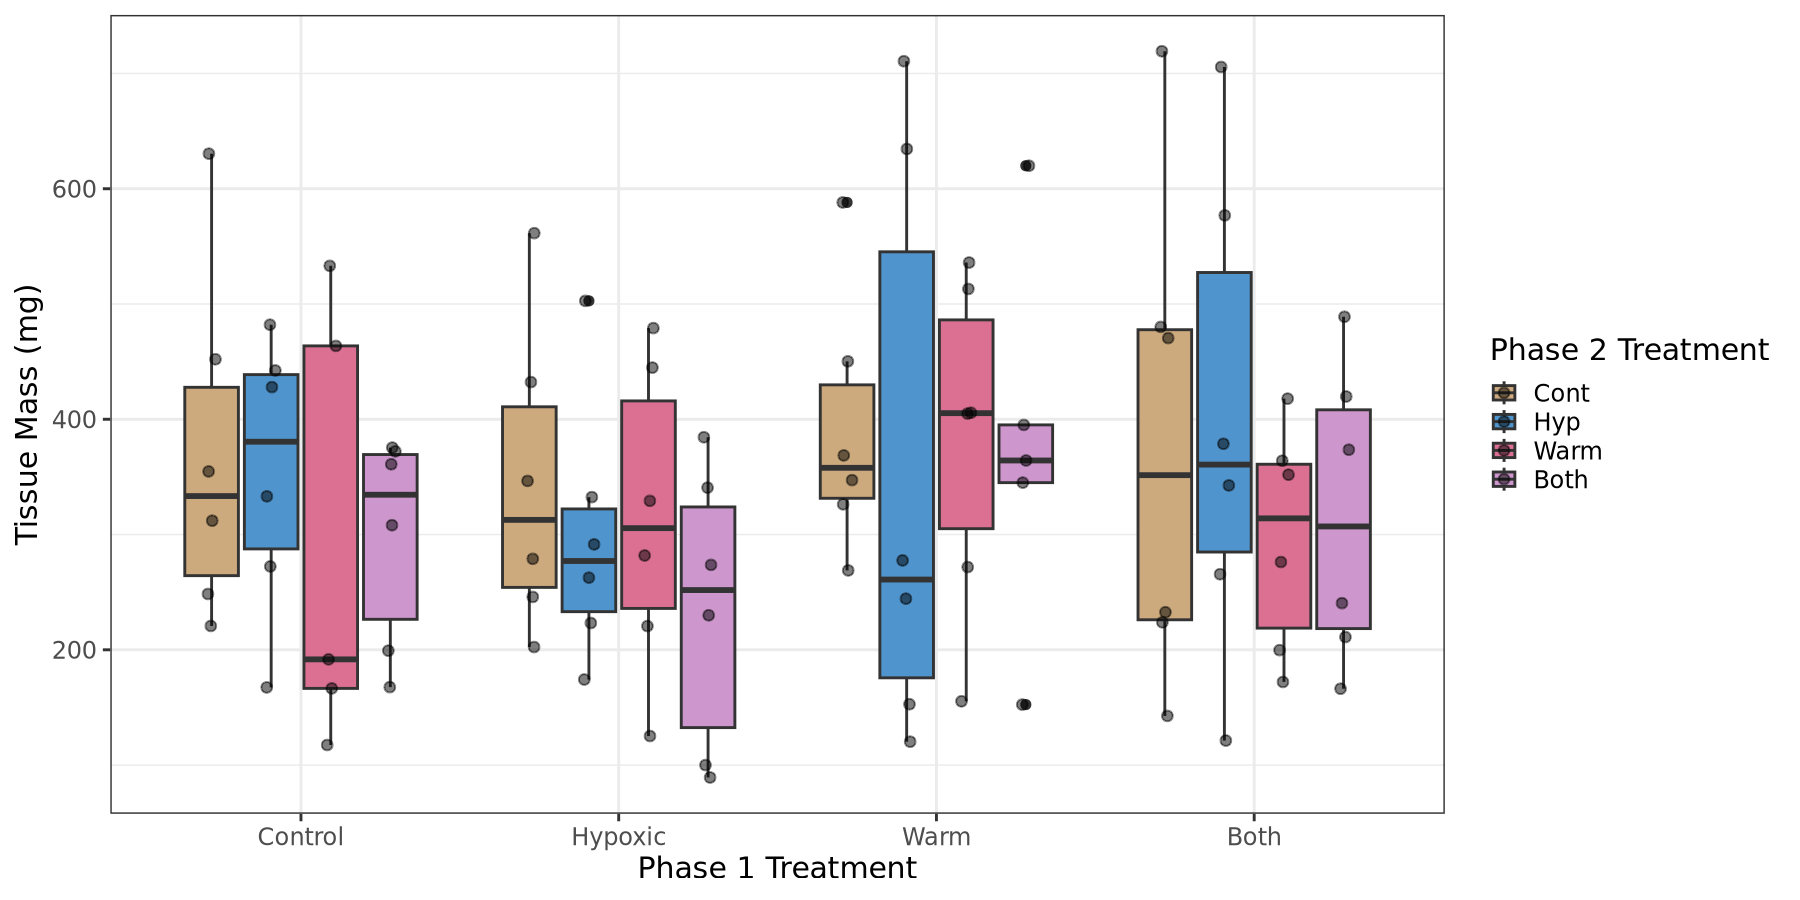

In [12]:
options(repr.plot.height = 7.5, repr.plot.width = 15)

ggplot(p2.mass, aes(x = Phase1_treatment, y = Actual_tissue_post_mg, fill = Phase2_treatment)) +
geom_boxplot() +
geom_point(position = position_jitterdodge(jitter.width = 0.1, dodge.width = 0.75),
             alpha = 0.5) +
scale_fill_manual(values = c("Hyp" = "steelblue3", "Warm" = "palevioletred", "Cont" = "burlywood3", "Both" = "plum3")) +
    scale_x_discrete(labels = c("Hyp" = "Hypoxic", "Cont" = "Control", "Warm" = "Warm", "Both" = "Both")) +
labs(x = 'Phase 1 Treatment',
     fill = 'Phase 2 Treatment',
     y = 'Tissue Mass (mg)') +
theme_bw(base_size = 18)

plotting how Sophie does (mean and SE):

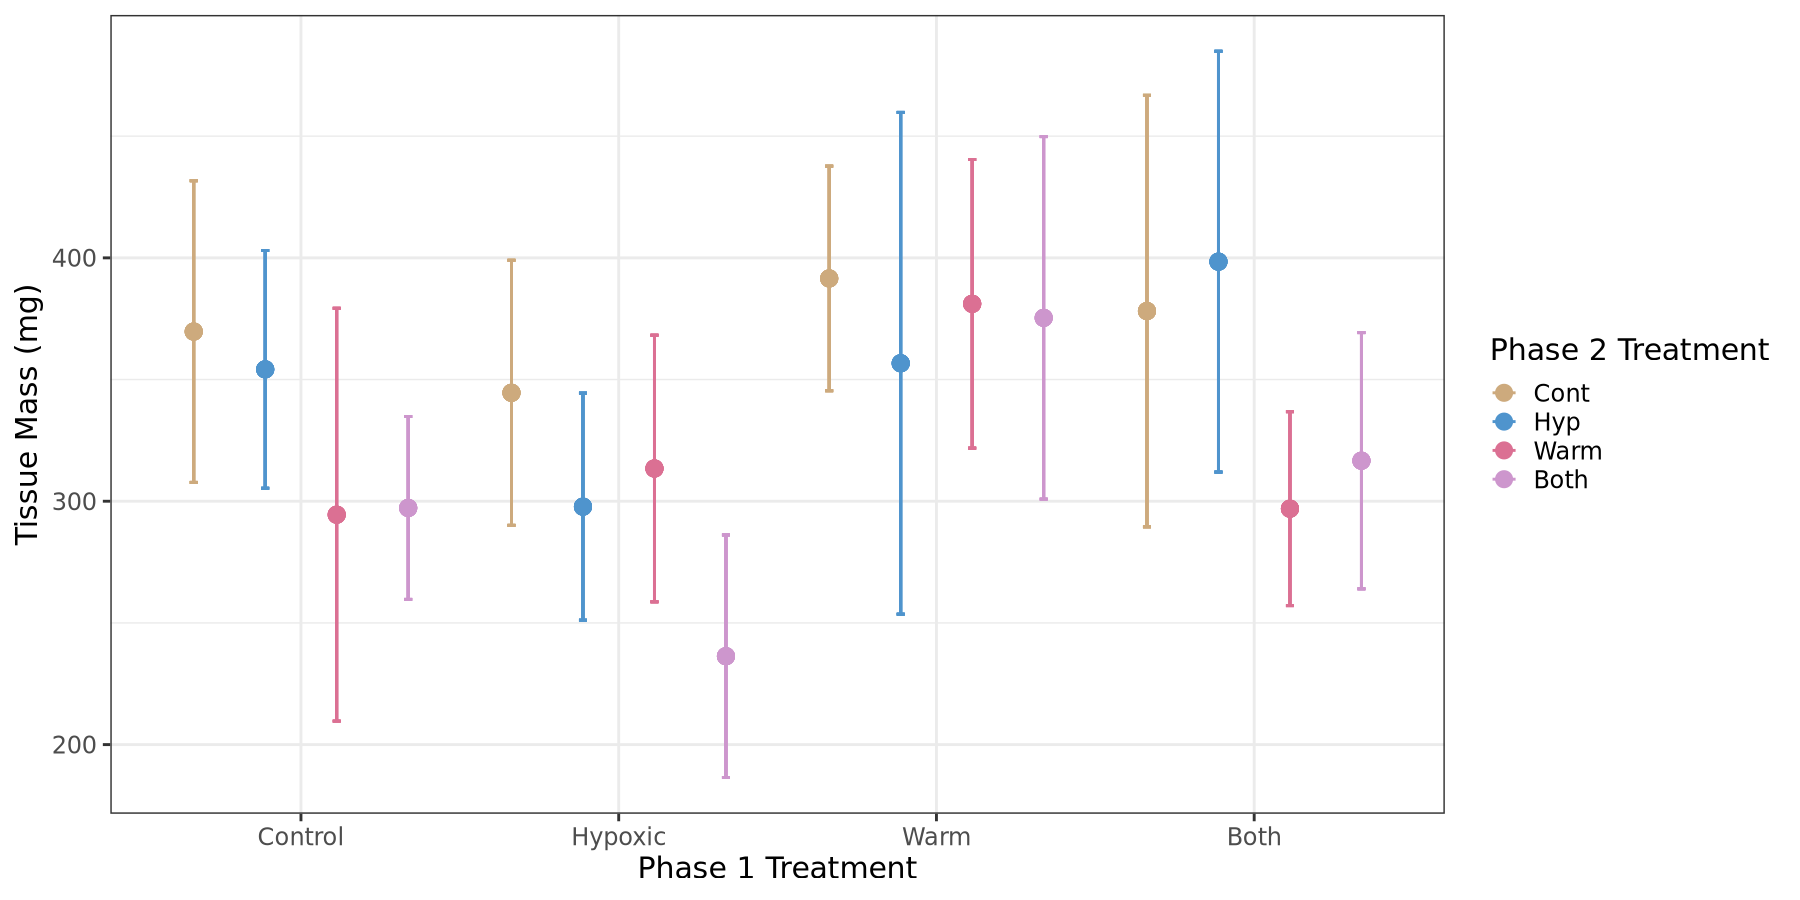

In [13]:
options(repr.plot.height = 7.5, repr.plot.width = 15)

post_summary_stats_t <- p2.mass %>%
  group_by(Phase1_treatment, Phase2_treatment) %>%
  mutate(
    mean_pre = mean(Actual_tissue_post_mg, na.rm = TRUE),
    se_pre = std.error(Actual_tissue_post_mg, na.rm = TRUE))

  #reorder effect of phase 1 Phase_1_treat
  post_summary_stats_t$Phase1_treatment <- factor(post_summary_stats_t$Phase1_treatment,levels = c("Cont", "Hyp","Warm", "Both"))
  post_summary_stats_t$Phase2_treatment <- factor(post_summary_stats_t$Phase2_treatment,levels = c("Cont", "Hyp","Warm", "Both"))
  
  #plot SHELL
  ggplot(post_summary_stats_t, aes(x = Phase1_treatment, y = mean_pre, color = Phase2_treatment)) +
    geom_point(size = 4, position = position_dodge(0.9)) + # Plot means as points
    geom_errorbar(aes(ymin = mean_pre - se_pre, ymax = mean_pre + se_pre), 
                  width = 0.1, position = position_dodge(0.9)) + # Error bars for SD
    theme_bw(base_size = 18)+
    scale_color_manual(values = c("Hyp" = "steelblue3", "Warm" = "palevioletred", "Cont" = "burlywood3", "Both" = "plum3")) +
    labs(x = "Phase 1 Treatment", 
         y = "Tissue Mass (mg)",
        color = 'Phase 2 Treatment') +
    scale_x_discrete(labels = c("Hyp" = "Hypoxic", "Cont" = "Control", "Warm" = "Warm", "Both" = "Both")) 

yea looks like the standard error is so huge for these samples that there's no significant interactions/terms 

but in general, looks like phase 1 control and hypoxia have, on average, lower final tissue mass - but also any recent exposure to warm (warm or both) results in lower final tissue mass?

#### stat testing:

In [14]:
m4 <- aov(Actual_tissue_post_mg ~ Phase1_DO * Phase1_temp * Phase2_DO * Phase2_temp, data = p2.mass)
aov_tab4 <- Anova(m4, test="F", type="III")

summary(m4)

#remove scientific notation
aov_tab4 %>%
  mutate(`Pr(>F)` = round(`Pr(>F)`, 4))

                                            Df  Sum Sq Mean Sq F value Pr(>F)
Phase1_DO                                    1   21877   21877   0.907  0.344
Phase1_temp                                  1   53478   53478   2.217  0.141
Phase2_DO                                    1    7817    7817   0.324  0.571
Phase2_temp                                  1   53436   53436   2.215  0.141
Phase1_DO:Phase1_temp                        1     119     119   0.005  0.944
Phase1_DO:Phase2_DO                          1     177     177   0.007  0.932
Phase1_temp:Phase2_DO                        1    6877    6877   0.285  0.595
Phase1_DO:Phase2_temp                        1    6736    6736   0.279  0.599
Phase1_temp:Phase2_temp                      1    1450    1450   0.060  0.807
Phase2_DO:Phase2_temp                        1      34      34   0.001  0.970
Phase1_DO:Phase1_temp:Phase2_DO              1   13542   13542   0.561  0.456
Phase1_DO:Phase1_temp:Phase2_temp            1   15982   15982  

,Sum Sq,Df,F value,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>
(Intercept),1.067841e+07,1,4.426208e+02,0.0000
Phase1_DO,2.072552e+04,1,8.590739e-01,0.3569
Phase1_temp,5.483943e+04,1,2.273097e+00,0.1357
Phase2_DO,6.897510e+03,1,2.859021e-01,0.5944
Phase2_temp,5.268799e+04,1,2.183919e+00,0.1435
Phase1_DO:Phase1_temp,2.966076e+01,1,1.229440e-03,0.9721
Phase1_DO:Phase2_DO,3.410727e+02,1,1.413748e-02,0.9057
Phase1_temp:Phase2_DO,6.773879e+03,1,2.807776e-01,0.5977
Phase1_DO:Phase2_temp,6.337470e+03,1,2.626884e-01,0.6097


no significant difference of final mass between treatments

diagnostics

,Df,F value,Pr(>F)
,<int>,<dbl>,<dbl>
group,15,0.7380837,0.7389068
,78,NA,NA


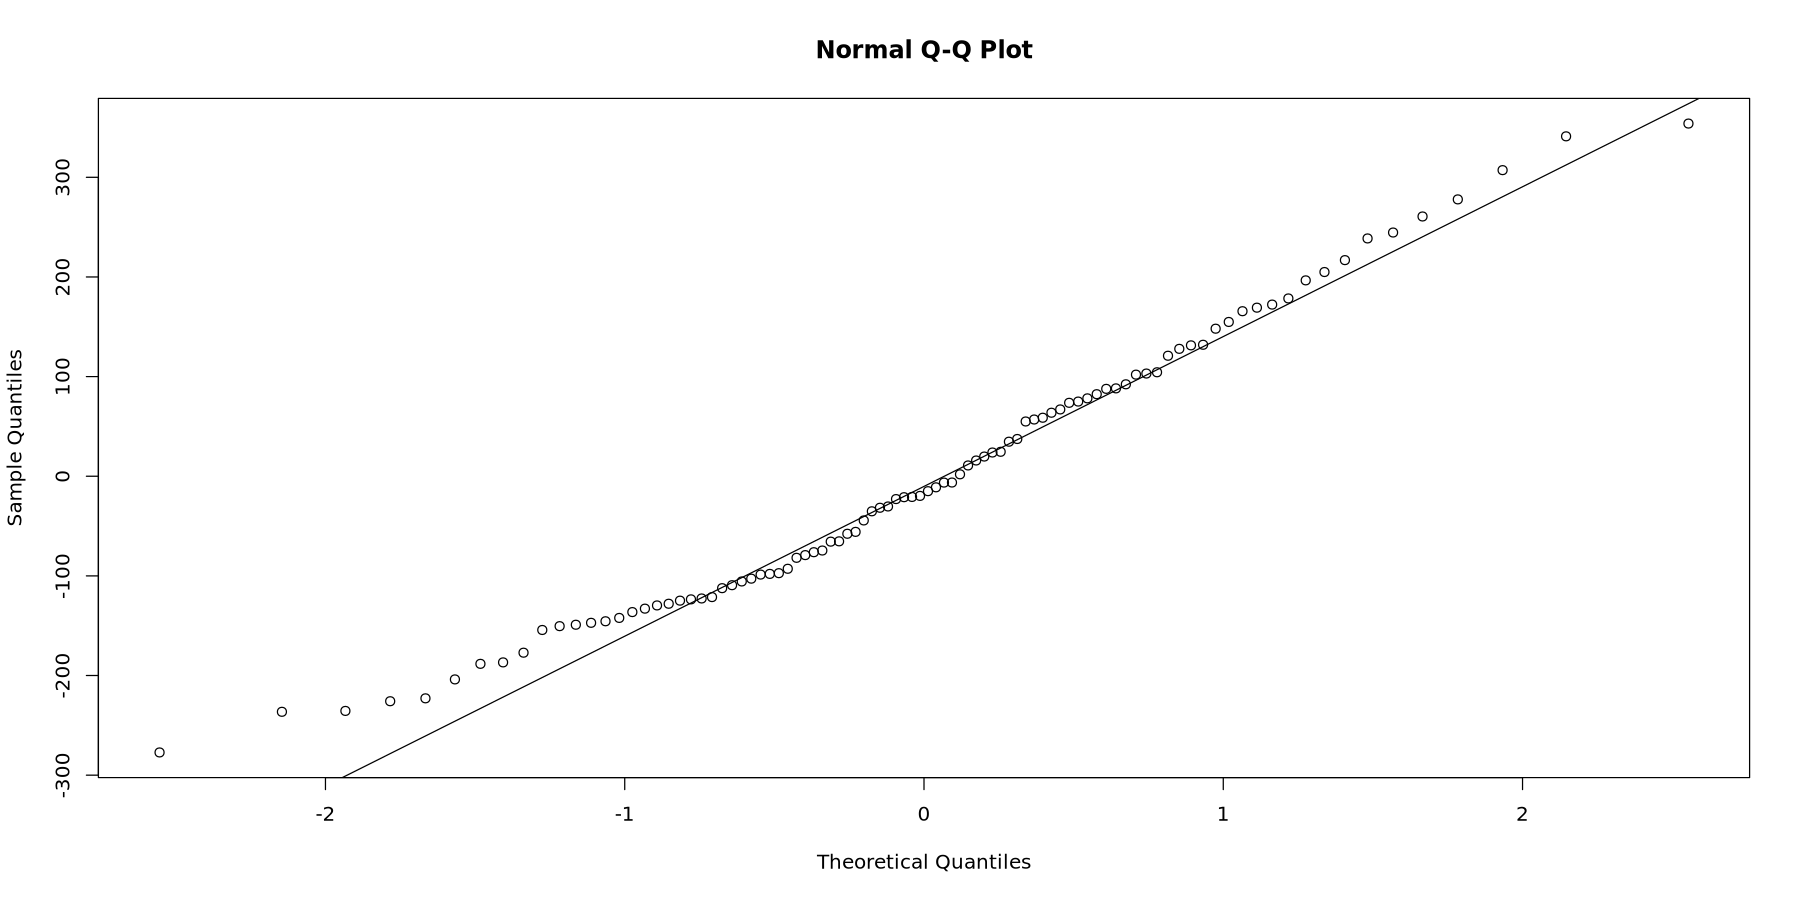

In [15]:
leveneTest((Actual_tissue_post_mg) ~ Phase1_temp * Phase1_DO * Phase2_temp * Phase2_DO, p2.mass)
m4.e <- residuals(m4) 
qqnorm(m4.e)
qqline(m4.e)

### shell

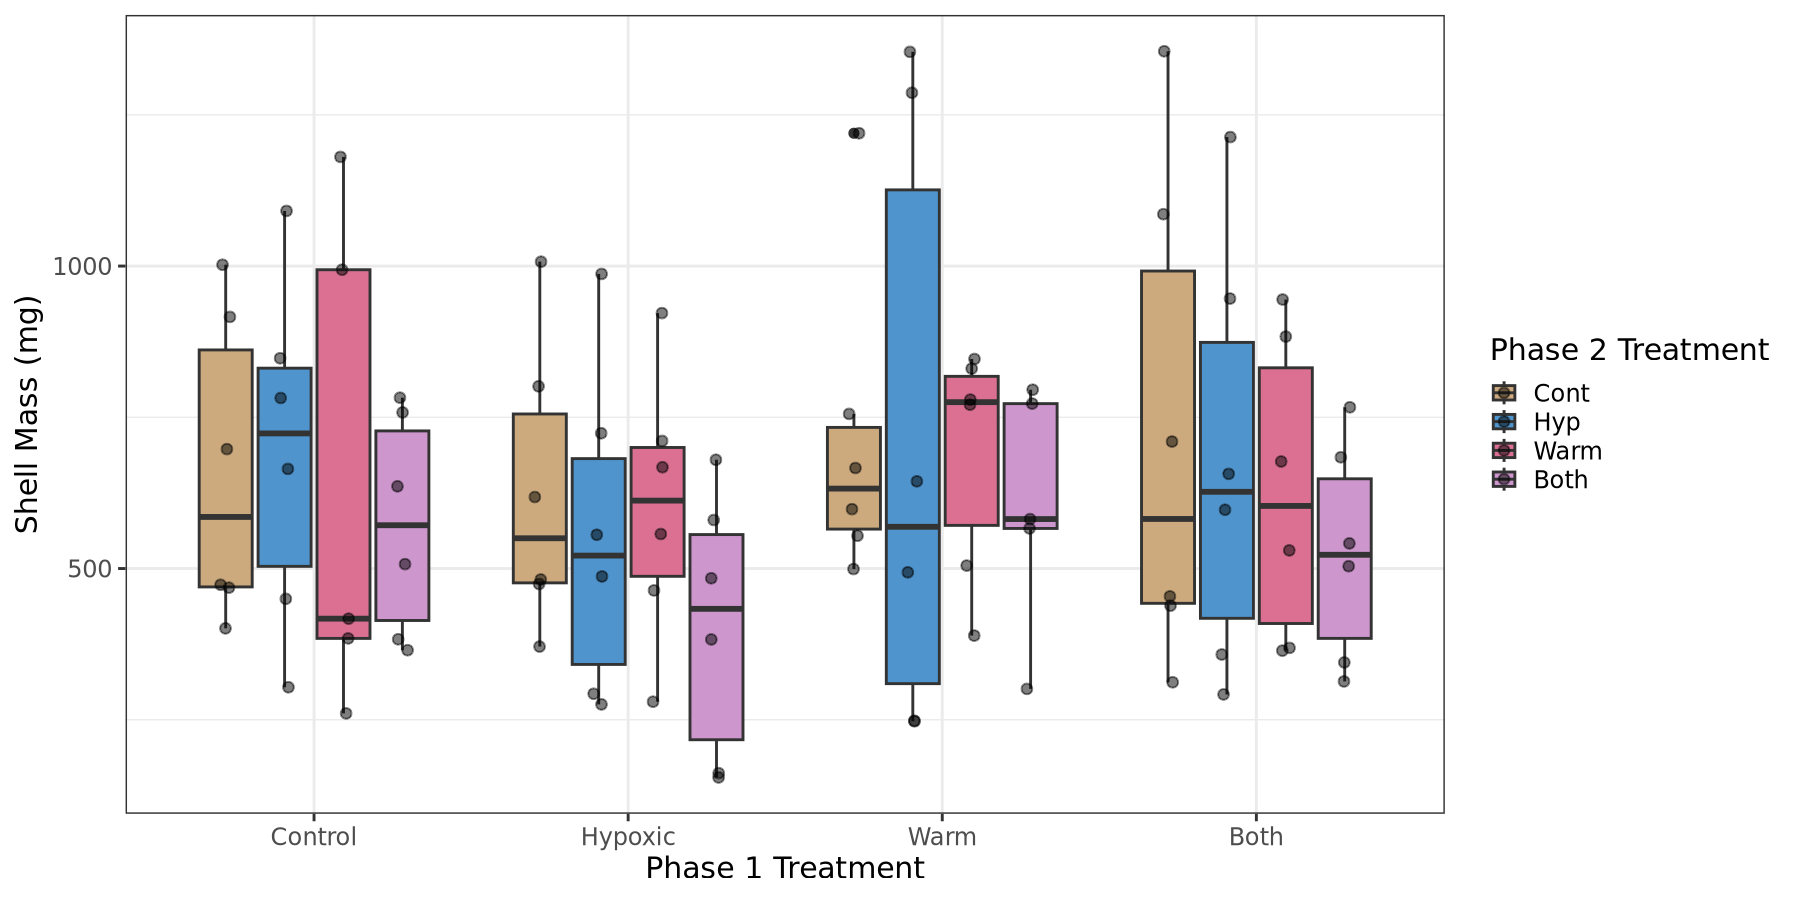

In [16]:
options(repr.plot.height = 7.5, repr.plot.width = 15)

ggplot(p2.mass, aes(x = Phase1_treatment, y = Actual_shell_post_mg, fill = Phase2_treatment)) +
geom_boxplot() +
geom_point(position = position_jitterdodge(jitter.width = 0.1, dodge.width = 0.75),
             alpha = 0.5) +
scale_fill_manual(values = c("Hyp" = "steelblue3", "Warm" = "palevioletred", "Cont" = "burlywood3", "Both" = "plum3")) +
    scale_x_discrete(labels = c("Hyp" = "Hypoxic", "Cont" = "Control", "Warm" = "Warm", "Both" = "Both")) +
labs(x = 'Phase 1 Treatment',
     fill = 'Phase 2 Treatment',
     y = 'Shell Mass (mg)') +
theme_bw(base_size = 18)

plotting how Sophie does (mean and SE):

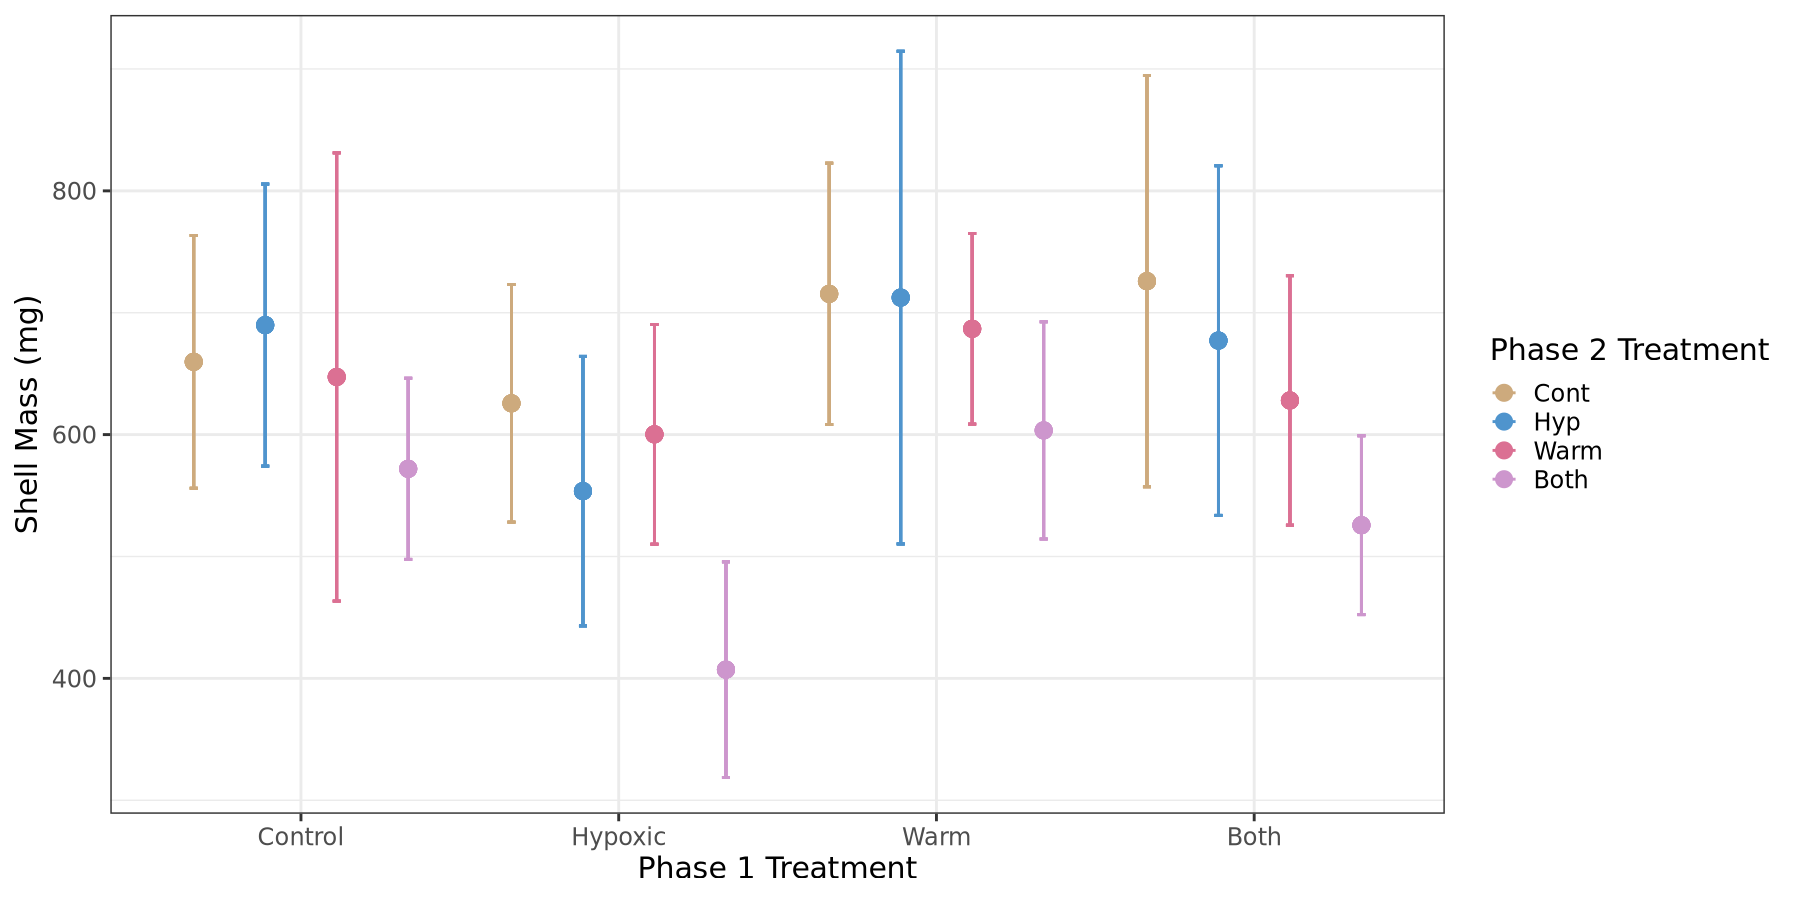

In [17]:
options(repr.plot.height = 7.5, repr.plot.width = 15)

post_summary_stats_s <- p2.mass %>%
  group_by(Phase1_treatment, Phase2_treatment) %>%
  mutate(
    mean_pre = mean(Actual_shell_post_mg, na.rm = TRUE),
    se_pre = std.error(Actual_shell_post_mg, na.rm = TRUE))

  #reorder effect of phase 1 Phase_1_treat
  post_summary_stats_s$Phase1_treatment <- factor(post_summary_stats_s$Phase1_treatment,levels = c("Cont", "Hyp","Warm", "Both"))
  post_summary_stats_s$Phase2_treatment <- factor(post_summary_stats_s$Phase2_treatment,levels = c("Cont", "Hyp","Warm", "Both"))
  
  #plot SHELL
  ggplot(post_summary_stats_s, aes(x = Phase1_treatment, y = mean_pre, color = Phase2_treatment)) +
    geom_point(size = 4, position = position_dodge(0.9)) + # Plot means as points
    geom_errorbar(aes(ymin = mean_pre - se_pre, ymax = mean_pre + se_pre), 
                  width = 0.1, position = position_dodge(0.9)) + # Error bars for SD
    theme_bw(base_size = 18)+
    scale_color_manual(values = c("Hyp" = "steelblue3", "Warm" = "palevioletred", "Cont" = "burlywood3", "Both" = "plum3")) +
    labs(x = "Phase 1 Treatment", 
         y = "Shell Mass (mg)", 
        color = 'Phase 2 Treatment') +
    scale_x_discrete(labels = c("Hyp" = "Hypoxic", "Cont" = "Control", "Warm" = "Warm", "Both" = "Both")) 

early exposure to hypoxia results in decreased final shell mass (especially in HB samples)

but again, SE is so large that there are no significant interactions/terms

#### stat testing:

In [18]:
m5 <- aov(Actual_shell_post_mg ~ Phase1_DO * Phase1_temp * Phase2_DO * Phase2_temp, data = p2.mass)
aov_tab5 <- Anova(m5, test="F", type="III")

summary(m5)

#remove scientific notation
aov_tab5 %>%
  mutate(`Pr(>F)` = round(`Pr(>F)`, 4))

                                            Df  Sum Sq Mean Sq F value Pr(>F)
Phase1_DO                                    1  113404  113404   1.349  0.249
Phase1_temp                                  1  106251  106251   1.264  0.264
Phase2_DO                                    1  107359  107359   1.278  0.262
Phase2_temp                                  1  175623  175623   2.090  0.152
Phase1_DO:Phase1_temp                        1   17509   17509   0.208  0.649
Phase1_DO:Phase2_DO                          1   31546   31546   0.375  0.542
Phase1_temp:Phase2_DO                        1    1886    1886   0.022  0.881
Phase1_DO:Phase2_temp                        1    8890    8890   0.106  0.746
Phase1_temp:Phase2_temp                      1    2216    2216   0.026  0.871
Phase2_DO:Phase2_temp                        1   47956   47956   0.571  0.452
Phase1_DO:Phase1_temp:Phase2_DO              1    8964    8964   0.107  0.745
Phase1_DO:Phase1_temp:Phase2_temp            1    1815    1815  

,Sum Sq,Df,F value,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>
(Intercept),3.680865e+07,1,4.380107e+02,0.0000
Phase1_DO,1.080774e+05,1,1.286086e+00,0.2602
Phase1_temp,9.870170e+04,1,1.174517e+00,0.2818
Phase2_DO,1.098097e+05,1,1.306699e+00,0.2565
Phase2_temp,1.737852e+05,1,2.067986e+00,0.1544
Phase1_DO:Phase1_temp,1.782437e+04,1,2.121041e-01,0.6464
Phase1_DO:Phase2_DO,2.961999e+04,1,3.524680e-01,0.5544
Phase1_temp:Phase2_DO,1.940343e+03,1,2.308943e-02,0.8796
Phase1_DO:Phase2_temp,8.599608e+03,1,1.023325e-01,0.7499


no significant effect of treatments on final mass of the oyster

diagnostics

,Df,F value,Pr(>F)
,<int>,<dbl>,<dbl>
group,15,0.9152072,0.5509033
,78,NA,NA


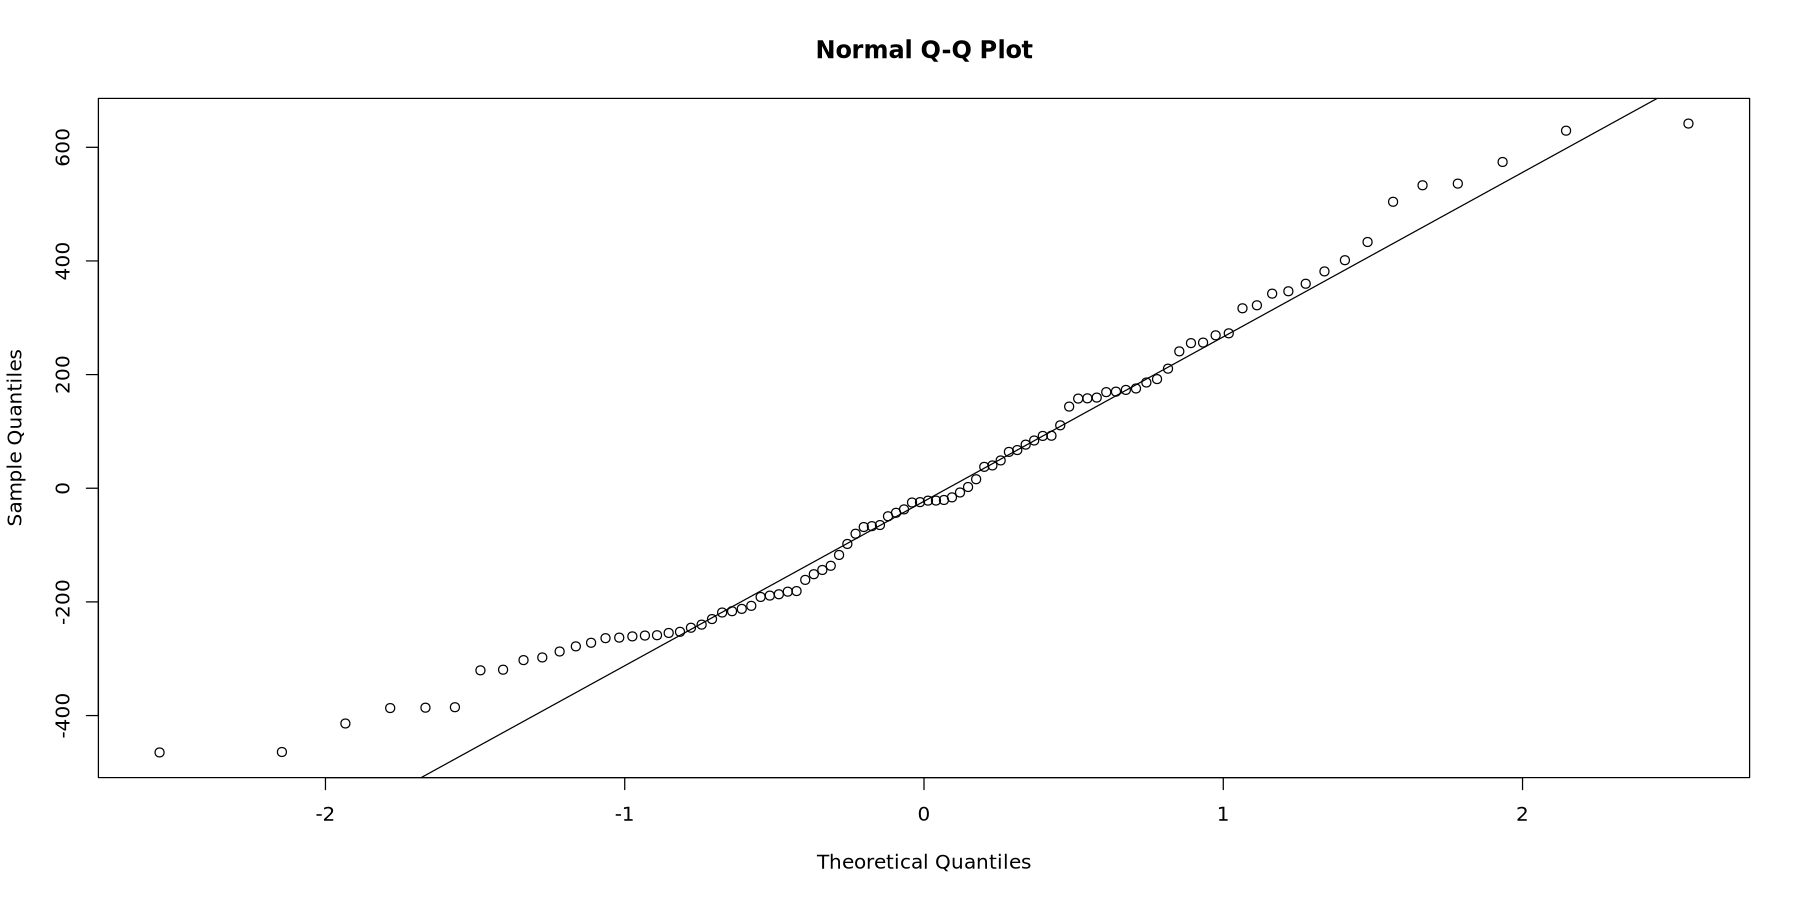

In [19]:
leveneTest((Actual_shell_post_mg) ~ Phase1_temp * Phase1_DO * Phase2_temp * Phase2_DO, p2.mass)
m5.e <- residuals(m5) 
qqnorm(m5.e)
qqline(m5.e)

### tissue:shell

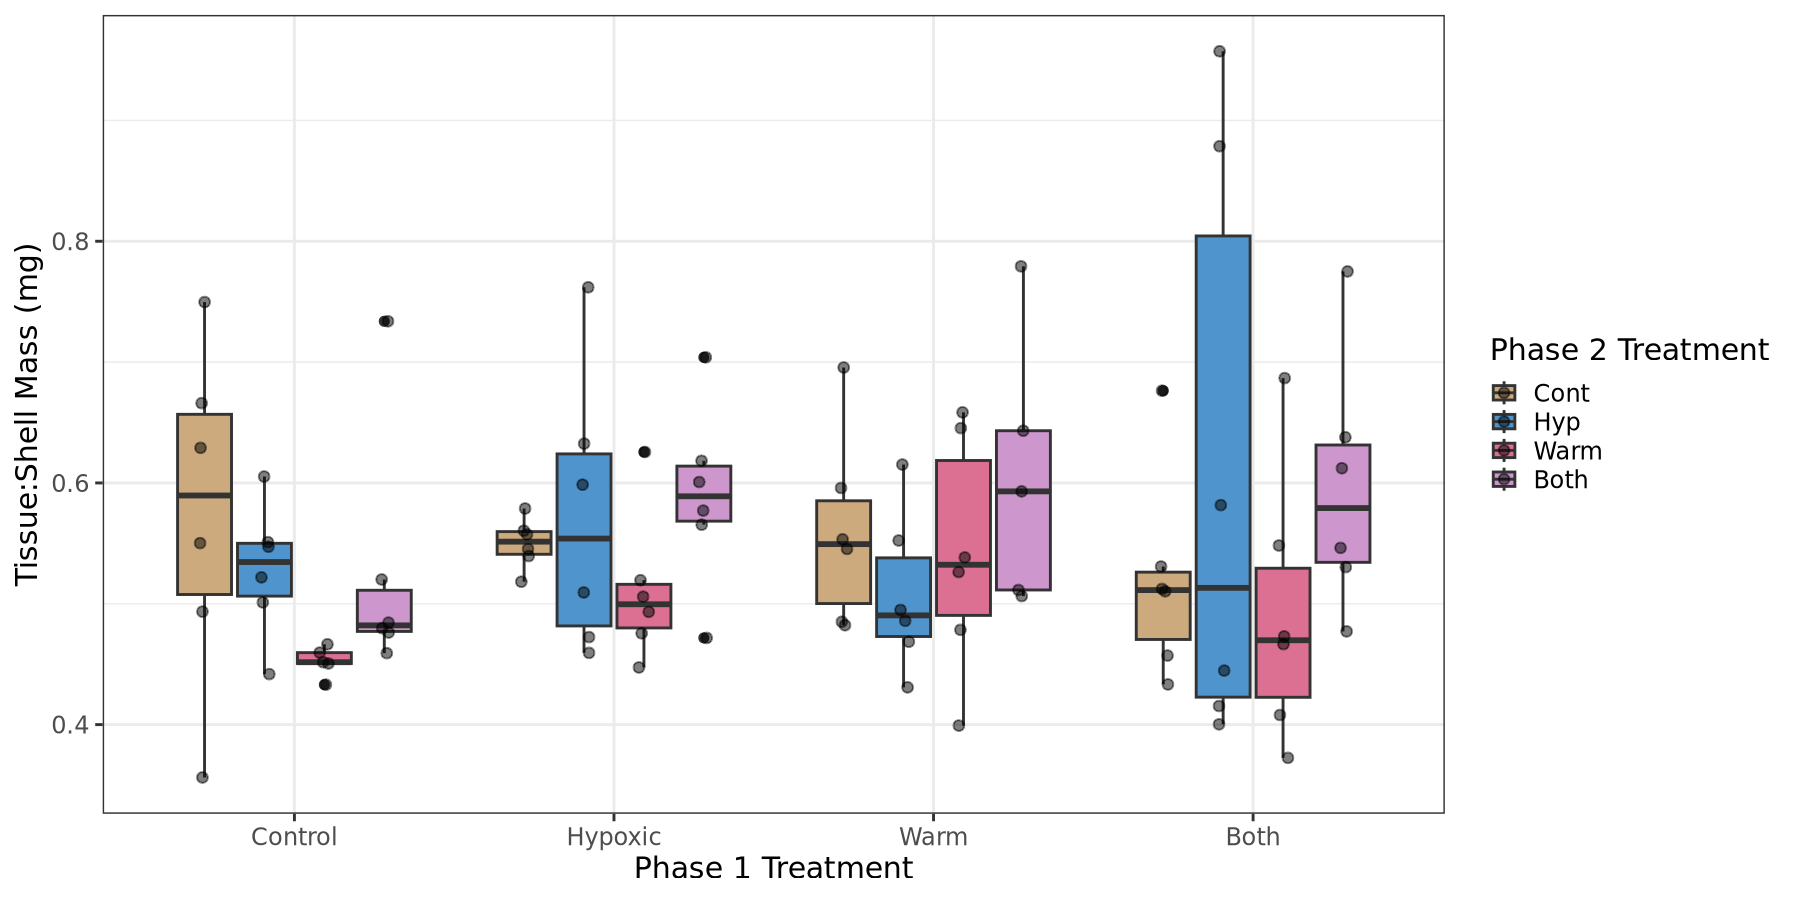

In [20]:
ggplot(p2.mass, aes(x = Phase1_treatment, y = Ratio_tissue_shell_mg, fill = Phase2_treatment)) +
geom_boxplot() +
geom_point(position = position_jitterdodge(jitter.width = 0.1, dodge.width = 0.75),
             alpha = 0.5) +
scale_fill_manual(values = c("Hyp" = "steelblue3", "Warm" = "palevioletred", "Cont" = "burlywood3", "Both" = "plum3")) +
    scale_x_discrete(labels = c("Hyp" = "Hypoxic", "Cont" = "Control", "Warm" = "Warm", "Both" = "Both")) +
labs(x = 'Phase 1 Treatment',
     fill = 'Phase 2 Treatment',
     y = 'Tissue:Shell Mass (mg)') +
theme_bw(base_size = 18)

hmm okay looks like a lot of context-dependent patterns (treatments behave differently depending on the early life treatment)

plotting how Sophie does (mean and SE):

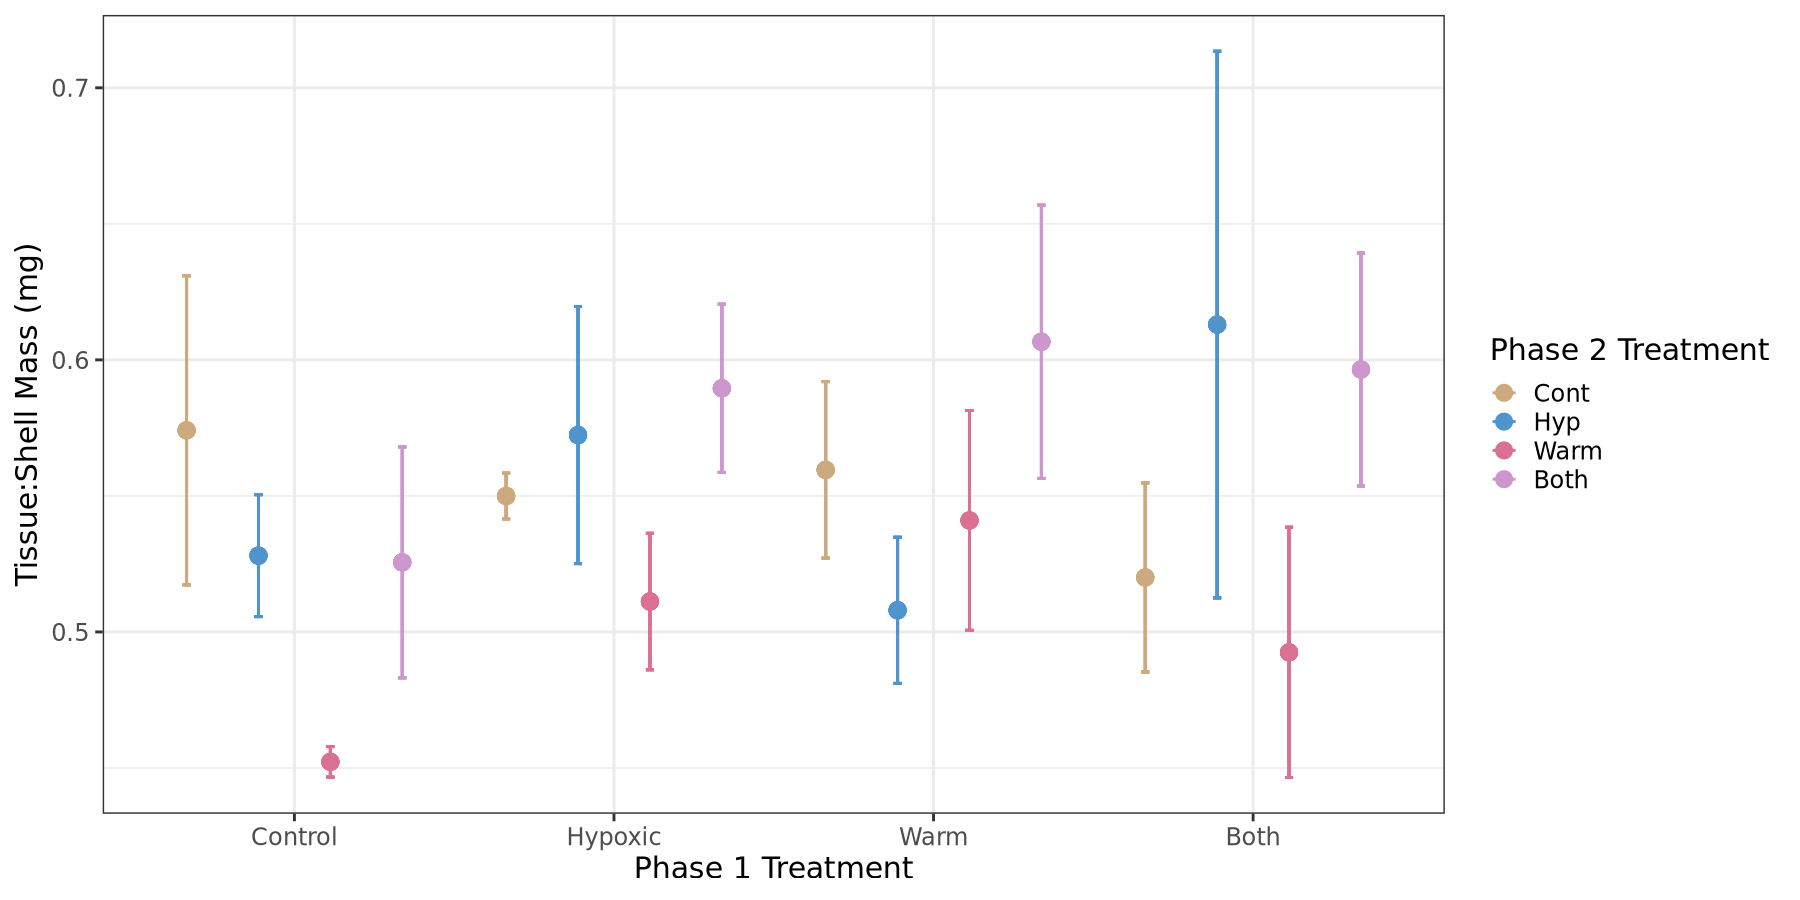

In [21]:
post_summary_stats_r <- p2.mass %>%
  group_by(Phase1_treatment, Phase2_treatment) %>%
  mutate(
    mean_pre = mean(Ratio_tissue_shell_mg, na.rm = TRUE),
    se_pre = std.error(Ratio_tissue_shell_mg, na.rm = TRUE))

  #reorder effect of phase 1 Phase_1_treat
  post_summary_stats_r$Phase1_treatment <- factor(post_summary_stats_r$Phase1_treatment,levels = c("Cont", "Hyp","Warm", "Both"))
  post_summary_stats_r$Phase2_treatment <- factor(post_summary_stats_r$Phase2_treatment,levels = c("Cont", "Hyp","Warm", "Both"))
  
  #plot RATIO
  ggplot(post_summary_stats_r, aes(x = Phase1_treatment, y = mean_pre, color = Phase2_treatment)) +
    geom_point(size = 4, position = position_dodge(0.9)) + # Plot means as points
    geom_errorbar(aes(ymin = mean_pre - se_pre, ymax = mean_pre + se_pre), 
                  width = 0.1, position = position_dodge(0.9)) + # Error bars for SD
    theme_bw(base_size = 18)+
    scale_color_manual(values = c("Hyp" = "steelblue3", "Warm" = "palevioletred", "Cont" = "burlywood3", "Both" = "plum3")) +
    labs(x = "Phase 1 Treatment", 
         y = "Tissue:Shell Mass (mg)",
        color = 'Phase 2 Treatment') +
    scale_x_discrete(labels = c("Hyp" = "Hypoxic", "Cont" = "Control", "Warm" = "Warm", "Both" = "Both")) 

#### stat testing:

In [22]:
m6 <- aov(Ratio_tissue_shell_mg ~ Phase1_DO * Phase1_temp * Phase2_DO * Phase2_temp, data = p2.mass)
aov_tab6 <- Anova(m6, test="F", type="III")

summary(m6)

#remove scientific notation
aov_tab6 %>%
  mutate(`Pr(>F)` = round(`Pr(>F)`, 4))

                                            Df Sum Sq Mean Sq F value Pr(>F)  
Phase1_DO                                    1 0.0080 0.00796   0.695 0.4069  
Phase1_temp                                  1 0.0045 0.00450   0.393 0.5328  
Phase2_DO                                    1 0.0381 0.03815   3.331 0.0718 .
Phase2_temp                                  1 0.0044 0.00441   0.385 0.5366  
Phase1_DO:Phase1_temp                        1 0.0055 0.00550   0.480 0.4904  
Phase1_DO:Phase2_DO                          1 0.0280 0.02801   2.446 0.1218  
Phase1_temp:Phase2_DO                        1 0.0027 0.00265   0.232 0.6316  
Phase1_DO:Phase2_temp                        1 0.0002 0.00021   0.019 0.8920  
Phase1_temp:Phase2_temp                      1 0.0101 0.01006   0.879 0.3515  
Phase2_DO:Phase2_temp                        1 0.0317 0.03171   2.769 0.1001  
Phase1_DO:Phase1_temp:Phase2_DO              1 0.0044 0.00437   0.382 0.5385  
Phase1_DO:Phase1_temp:Phase2_temp            1 0.018

,Sum Sq,Df,F value,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>
(Intercept),2.794770e+01,1,2.440739e+03,0.0000
Phase1_DO,8.217053e-03,1,7.176148e-01,0.3995
Phase1_temp,6.577020e-03,1,5.743868e-01,0.4508
Phase2_DO,4.203446e-02,1,3.670969e+00,0.0590
Phase2_temp,4.416167e-03,1,3.856743e-01,0.5364
Phase1_DO:Phase1_temp,6.799724e-03,1,5.938361e-01,0.4433
Phase1_DO:Phase2_DO,2.404316e-02,1,2.099746e+00,0.1513
Phase1_temp:Phase2_DO,2.518207e-03,1,2.199210e-01,0.6404
Phase1_DO:Phase2_temp,1.682124e-04,1,1.469039e-02,0.9038


nearly a significant effect of phase 2 DO on the ratio of tissue:shell mass

diagnostics

,Df,F value,Pr(>F)
,<int>,<dbl>,<dbl>
group,15,2.107884,0.01780982
,78,NA,NA


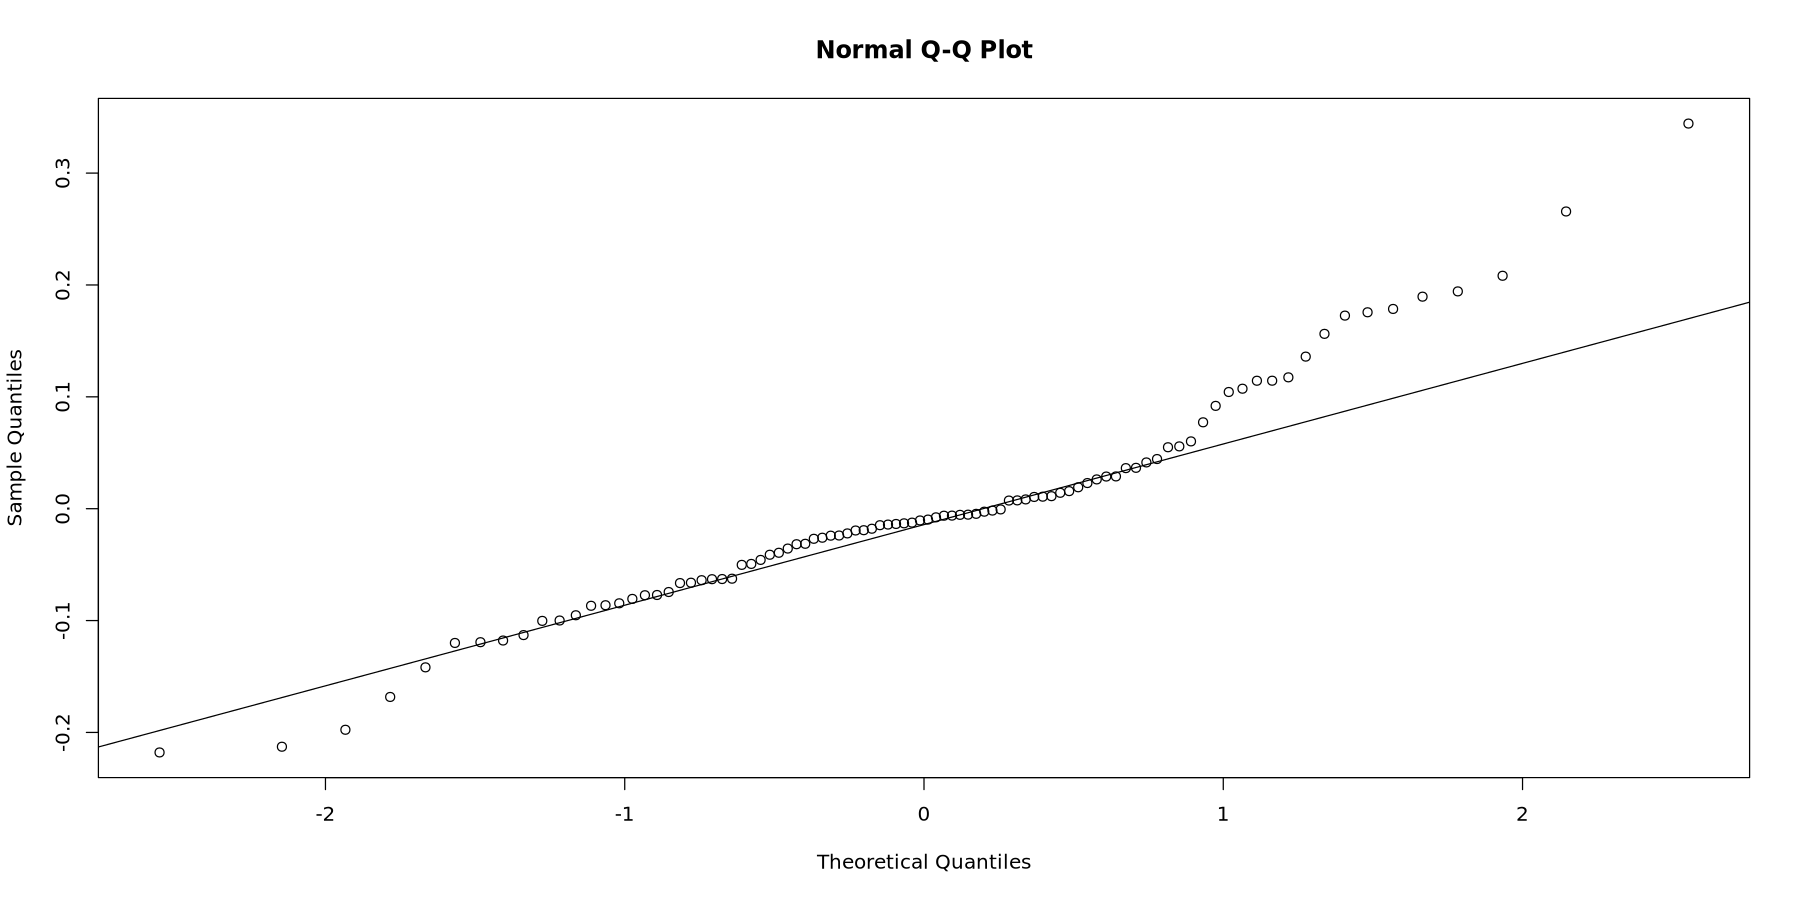

In [23]:
leveneTest((Ratio_tissue_shell_mg) ~ Phase1_temp * Phase1_DO * Phase2_temp * Phase2_DO, p2.mass)
m6.e <- residuals(m6) 
qqnorm(m6.e)
qqline(m6.e)

fails the leven test (so there are unequal variances between groups)

In [24]:
p2.mass$cell <- interaction(p2.mass$Phase1_temp, p2.mass$Phase1_DO,
                            p2.mass$Phase2_temp, p2.mass$Phase2_DO, drop = TRUE)
v <- tapply(log(p2.mass$Ratio_tissue_shell_mg), p2.mass$cell, var, na.rm = TRUE)
sort(v)
max(v) / min(v)

Ambient.Norm.Warm.Norm  Ambient.Hyp.Ambient.Norm  Ambient.Norm.Ambient.Hyp 
             0.0007785597              0.0014254695              0.0112575814 
    Ambient.Hyp.Warm.Norm     Warm.Norm.Ambient.Hyp      Ambient.Hyp.Warm.Hyp 
             0.0130601664              0.0159504325              0.0171381803 
   Warm.Norm.Ambient.Norm     Warm.Hyp.Ambient.Norm         Warm.Hyp.Warm.Hyp 
             0.0188352224              0.0238705577              0.0288469842 
    Ambient.Norm.Warm.Hyp        Warm.Norm.Warm.Hyp       Warm.Norm.Warm.Norm 
             0.0306616075              0.0318988195              0.0353495013 
  Ambient.Hyp.Ambient.Hyp        Warm.Hyp.Warm.Norm Ambient.Norm.Ambient.Norm 
             0.0382038640              0.0475139163              0.0699205241 
     Warm.Hyp.Ambient.Hyp 
             0.1485750958

[1] 190.8333

In [25]:
# sensitivity analysis
m6 <- lm(log(Ratio_tissue_shell_mg) ~ Phase1_temp * Phase1_DO * Phase2_temp * Phase2_DO,
         data = p2.mass)

# normal anova - assumes equal variance - levene test says this is violated
Anova(m6, type = "II")
# unequal variances doesn't distort test statistics - onyl F and P values will change
Anova(m6, type = "II", white.adjust = "hc3")

,Sum Sq,Df,F value,Pr(>F)
,<dbl>,<dbl>,<dbl>,<dbl>
Phase1_temp,7.917913e-03,1,0.234493025,0.62956909
Phase1_DO,1.885899e-02,1,0.558518621,0.45710481
Phase2_temp,1.112739e-02,1,0.329543432,0.56757983
Phase2_DO,1.157697e-01,1,3.428578929,0.06786161
Phase1_temp:Phase1_DO,4.327070e-02,1,1.281483880,0.26109149
Phase1_temp:Phase2_temp,4.403701e-02,1,1.304178641,0.25694501
Phase1_DO:Phase2_temp,9.131192e-05,1,0.002704249,0.95865973
Phase1_temp:Phase2_DO,3.222063e-03,1,0.095423041,0.75821647
Phase1_DO:Phase2_DO,5.417544e-02,1,1.604433457,0.20904546


Coefficient covariances computed by hccm()



,Df,F,Pr(>F)
,<dbl>,<dbl>,<dbl>
Phase1_temp,1,0.0946485601,0.75916861
Phase1_DO,1,2.5497324198,0.11435669
Phase2_temp,1,1.1490014619,0.28706368
Phase2_DO,1,3.6472647269,0.05983791
Phase1_temp:Phase1_DO,1,2.0659018543,0.15462539
Phase1_temp:Phase2_temp,1,1.6528370754,0.20237708
Phase1_DO:Phase2_temp,1,0.2393037513,0.62608225
Phase1_temp:Phase2_DO,1,0.0336064120,0.85502223
Phase1_DO:Phase2_DO,1,0.7540694464,0.38785488


both tests highlight significant terms Phase2_DO (nearly signif) and Phase2_temp:Phase2_DO interaction - so unequal variances don't change the outcome of the tests

if the oyster is in ambient temperatures, then hypoxia doesn't have an effect on tissue:shell mass

if the oyster is in warm temperatures, then hypoxia has an effect on tissue:shell mass

In [26]:
res <- emmeans(m6, pairwise ~ Phase2_DO * Phase2_temp, adjust = "holm")
res$emmeans    # the group means
res$contrasts  # the comparisons between them

NOTE: Results may be misleading due to involvement in interactions



 Phase2_DO Phase2_temp emmean     SE df lower.CL upper.CL
 Norm      Ambient     -0.608 0.0375 78   -0.683   -0.534
 Hyp       Ambient     -0.614 0.0375 78   -0.688   -0.539
 Norm      Warm        -0.707 0.0384 78   -0.784   -0.630
 Hyp       Warm        -0.559 0.0384 78   -0.635   -0.482

Results are averaged over the levels of: Phase1_temp, Phase1_DO 
Results are given on the log (not the response) scale. 
Confidence level used: 0.95 

 contrast                   estimate     SE df t.ratio p.value
 Norm Ambient - Hyp Ambient  0.00531 0.0530 78   0.100  0.9243
 Norm Ambient - Norm Warm    0.09858 0.0537 78   1.836  0.3511
 Norm Ambient - Hyp Warm    -0.04979 0.0537 78  -0.927  0.9243
 Hyp Ambient - Norm Warm     0.09327 0.0537 78   1.737  0.3511
 Hyp Ambient - Hyp Warm     -0.05510 0.0537 78  -1.026  0.9243
 Norm Warm - Hyp Warm       -0.14837 0.0544 78  -2.730  0.0470

Results are averaged over the levels of: Phase1_temp, Phase1_DO 
Results are given on the log (not the response) scale. 
P value adjustment: holm method for 6 tests 

,contrast,estimate,SE,df,lower.CL,upper.CL
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,Norm Ambient - Hyp Ambient,0.005309219,0.05304565,78,-0.13829653,0.148914967
2,Norm Ambient - Norm Warm,0.098582567,0.05370463,78,-0.04680717,0.243972307
3,Norm Ambient - Hyp Warm,-0.049787049,0.05370463,78,-0.19517679,0.095602690
4,Hyp Ambient - Norm Warm,0.093273349,0.05370463,78,-0.05211639,0.238663088
5,Hyp Ambient - Hyp Warm,-0.055096268,0.05370463,78,-0.20048601,0.090293471
6,Norm Warm - Hyp Warm,-0.148369616,0.05435562,78,-0.29552172,-0.001217513


,contrast,estimate,SE,df,lower.CL,upper.CL,t.ratio,p.value
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,Norm Ambient - Hyp Ambient,0.005309219,0.05304565,78,-0.13829653,0.148914967,0.1000877,0.92431129
2,Norm Ambient - Norm Warm,0.098582567,0.05370463,78,-0.04680717,0.243972307,1.8356439,0.35110808
3,Norm Ambient - Hyp Warm,-0.049787049,0.05370463,78,-0.19517679,0.095602690,-0.9270533,0.92431129
4,Hyp Ambient - Norm Warm,0.093273349,0.05370463,78,-0.05211639,0.238663088,1.7367842,0.35110808
5,Hyp Ambient - Hyp Warm,-0.055096268,0.05370463,78,-0.20048601,0.090293471,-1.0259129,0.92431129
6,Norm Warm - Hyp Warm,-0.148369616,0.05435562,78,-0.29552172,-0.001217513,-2.7296097,0.04700644


NOTE: Results may be misleading due to involvement in interactions

Warning message:
“`aes_()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`
ℹ The deprecated feature was likely used in the emmeans package.
  Please report the issue at <https://github.com/rvlenth/emmeans/issues>.”


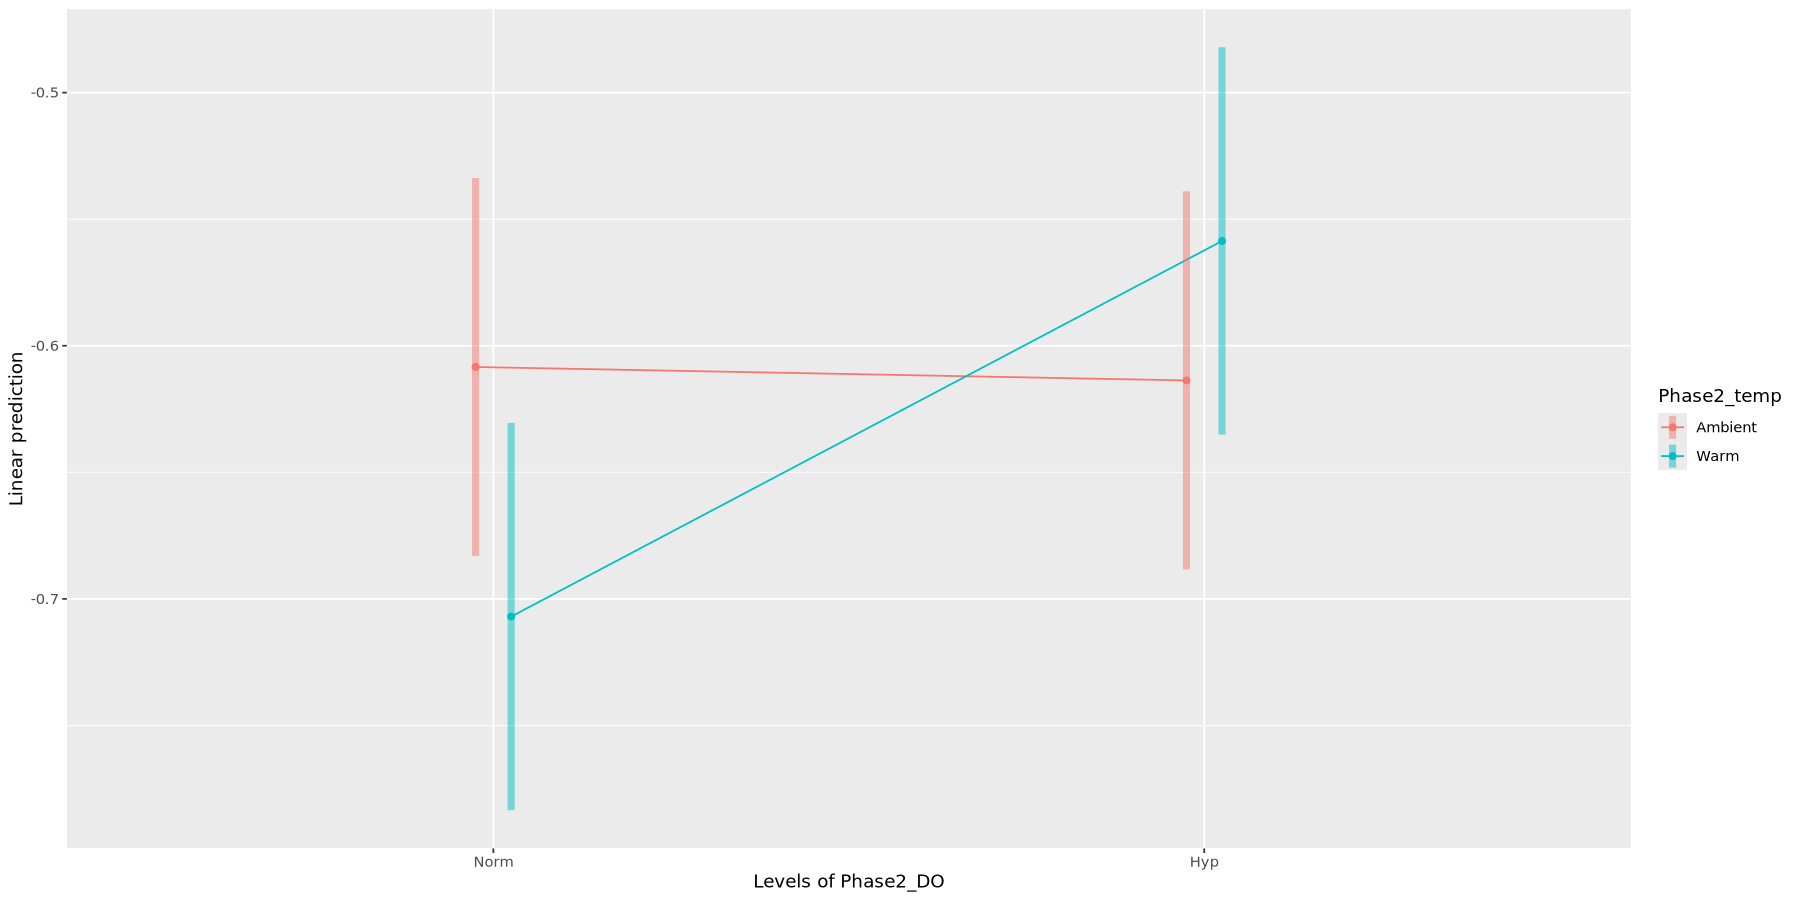

 contrast                   estimate     SE df t.ratio p.value
 Norm Ambient - Hyp Ambient  0.00531 0.0530 78   0.100  0.9996
 Norm Ambient - Norm Warm    0.09858 0.0537 78   1.836  0.2647
 Norm Ambient - Hyp Warm    -0.04979 0.0537 78  -0.927  0.7905
 Hyp Ambient - Norm Warm     0.09327 0.0537 78   1.737  0.3119
 Hyp Ambient - Hyp Warm     -0.05510 0.0537 78  -1.026  0.7348
 Norm Warm - Hyp Warm       -0.14837 0.0544 78  -2.730  0.0384

Results are averaged over the levels of: Phase1_temp, Phase1_DO 
Results are given on the log (not the response) scale. 
P value adjustment: tukey method for comparing a family of 4 estimates 

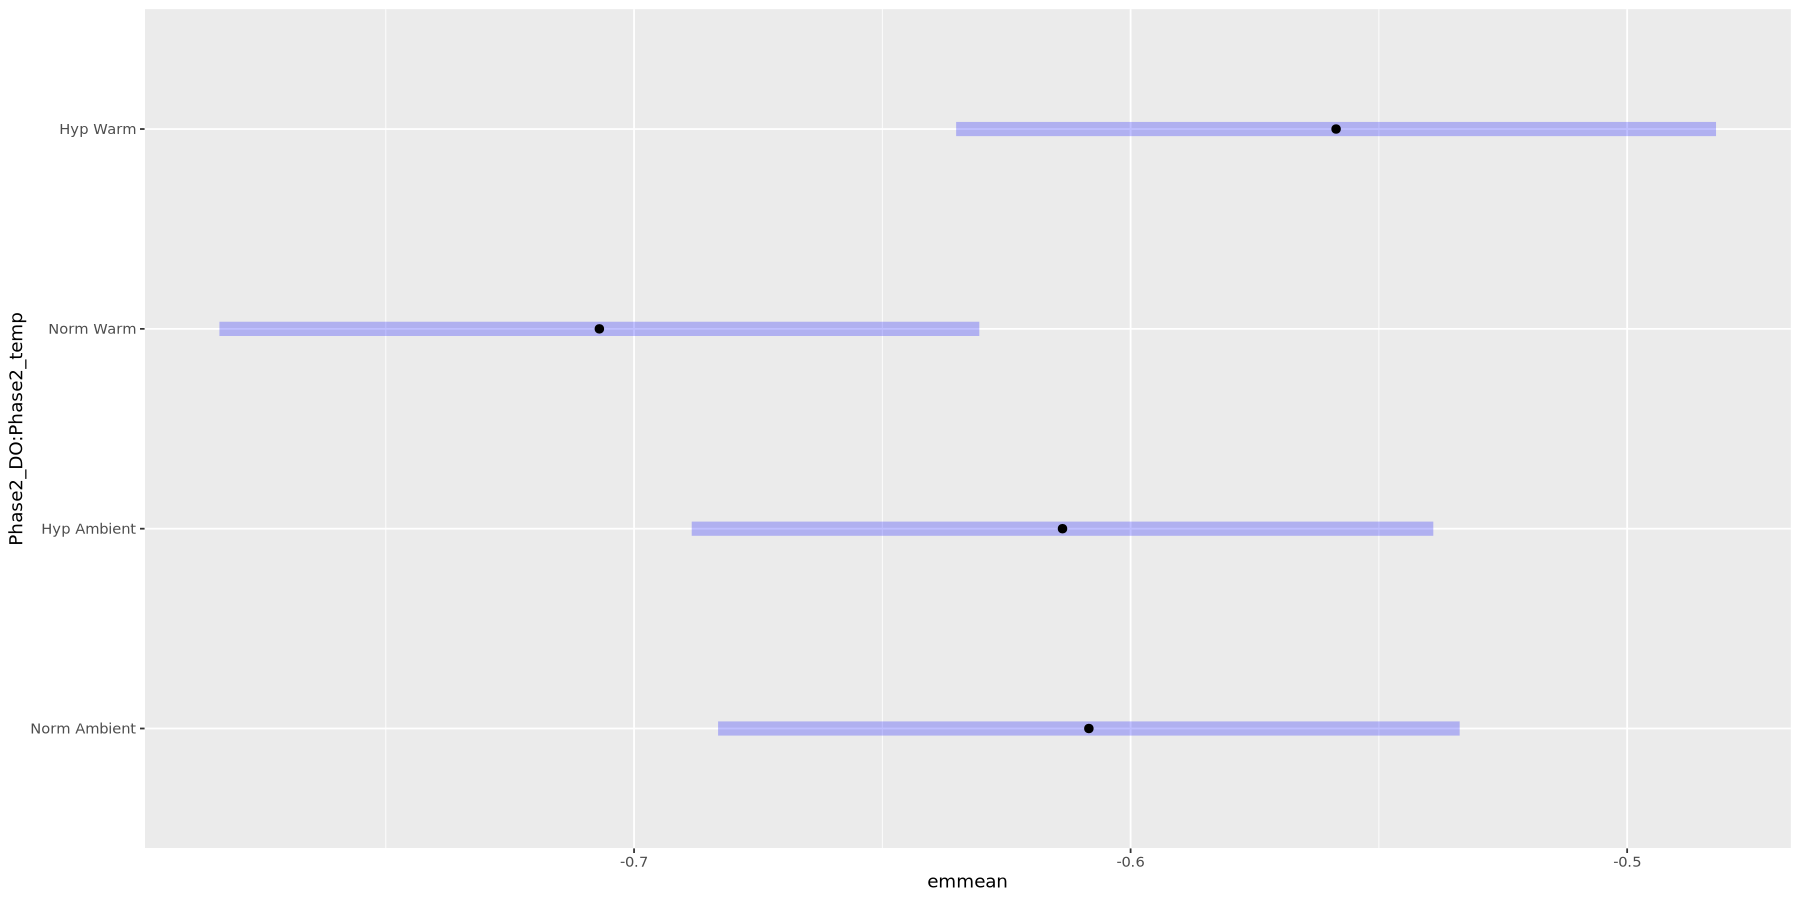

In [27]:
confint(res$contrasts)      # CIs for the differences, often more informative than p-values
summary(res$contrasts, infer = TRUE)   # estimates, CIs, t and p all together
emmip(m6, Phase2_temp ~ Phase2_DO, CIs = TRUE)   # plot of the interaction
plot(res$emmeans)           # means with CIs
pairs(res$emmeans)          # contrasts again, if you saved only the means

plotting significant terms/interactions

**phase 2 DO**

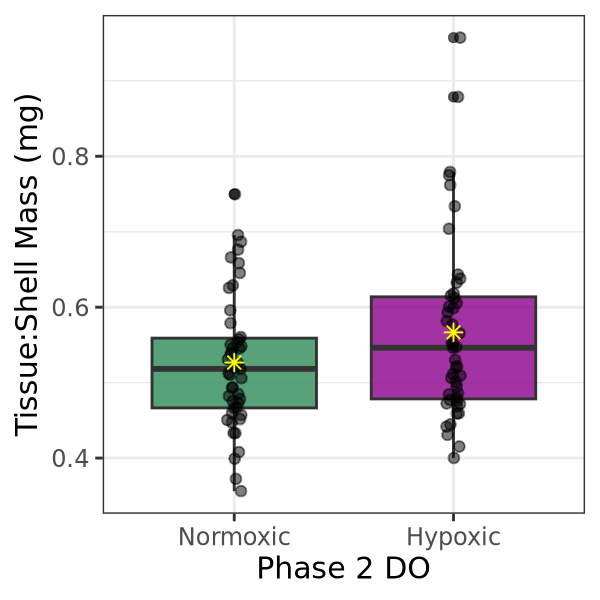

In [32]:
options(repr.plot.height = 5, repr.plot.width = 5)

ggplot(p2.mass, aes(x = Phase2_DO, y = Ratio_tissue_shell_mg, fill = Phase2_DO)) +
geom_boxplot(alpha = 0.8) +
geom_point(position = position_jitterdodge(jitter.width = 0.1, dodge.width = 0.75),
             alpha = 0.5) +
stat_summary(
    fun = "mean",
    geom = "point",
    shape = 8,
    size = 3,
    color = "yellow",
    position = position_dodge(width = 0.9)
  ) +
  scale_fill_manual(values = c("Hyp" = "darkmagenta", "Norm" = "seagreen")) +
    scale_x_discrete(labels = c("Hyp" = "Hypoxic", "Norm" = "Normoxic")) +
guides(fill = 'none') +
labs(x = 'Phase 2 DO',
     fill = 'Phase 2 DO',
     y = 'Tissue:Shell Mass (mg)') +
theme_bw(base_size = 18)

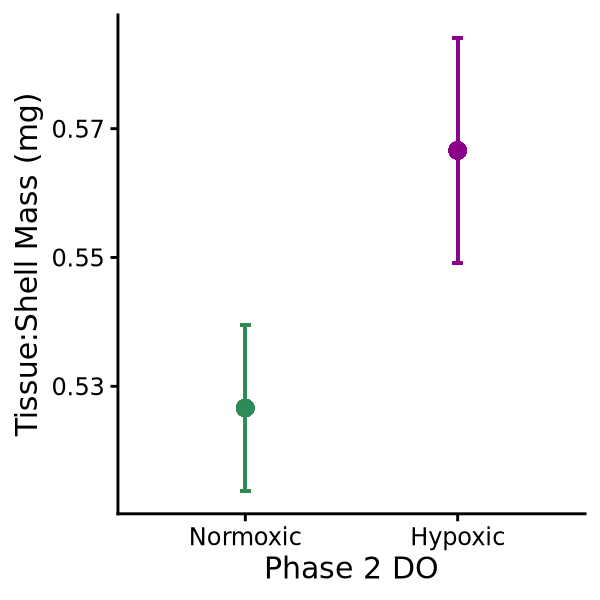

In [29]:
options(repr.plot.height = 5, repr.plot.width = 5)

pre_summary_stats_t <- p2.mass %>%
  group_by(Phase2_DO) %>%
  mutate(
    mean_pre = mean(Ratio_tissue_shell_mg, na.rm = TRUE),
    se_pre = std.error(Ratio_tissue_shell_mg, na.rm = TRUE))

#reorder
pre_summary_stats_t$Phase2_DO <- factor(pre_summary_stats_t$Phase2_DO, levels = c("Norm", "Hyp"))

#Tissue plot with mean and SD
ggplot(pre_summary_stats_t, aes(x = Phase2_DO, y = mean_pre, color = Phase2_DO)) +
  geom_point(size = 4, position = position_dodge(0.9)) + # Plot means as points
  geom_errorbar(aes(ymin = mean_pre - se_pre, ymax = mean_pre + se_pre), 
                width = 0.05, position = position_dodge(0.9)) + # Error bars for SD
  theme_classic(base_size = 18) +
  guides(color = "none") + # Remove legend for color
  scale_color_manual(values = c("Hyp" = "darkmagenta", "Norm" = "seagreen")) +
  scale_x_discrete(labels = c("Hyp" = "Hypoxic", "Norm" = "Normoxic")) +
  labs(x = "Phase 2 DO", y = "Tissue:Shell Mass (mg)") +
  theme(legend.position = "none") # Remove legend

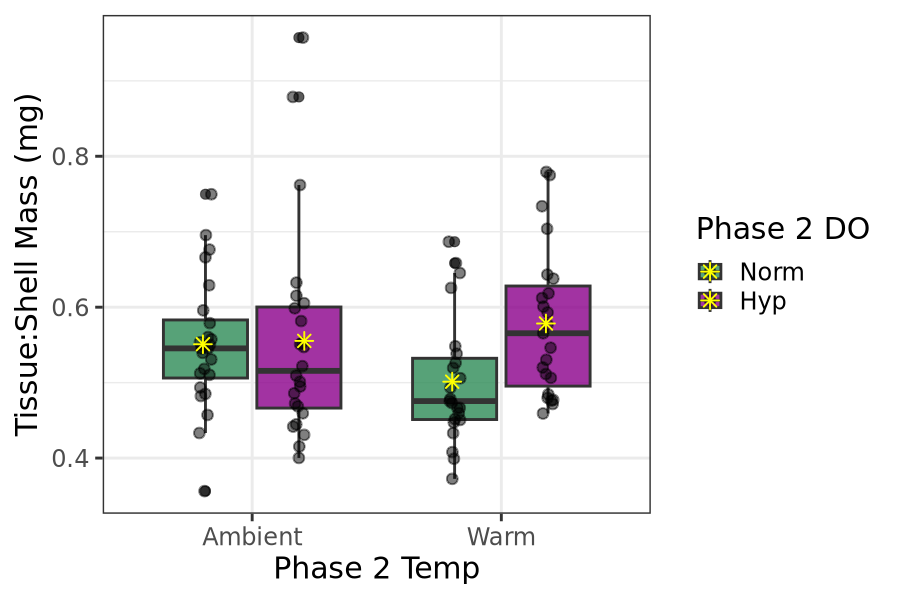

In [30]:
options(repr.plot.height = 5, repr.plot.width = 7.5)

ggplot(p2.mass, aes(x = Phase2_temp, y = Ratio_tissue_shell_mg, fill = Phase2_DO)) +
geom_boxplot(alpha = 0.8) +
geom_point(position = position_jitterdodge(jitter.width = 0.1, dodge.width = 0.75),
             alpha = 0.5) +
stat_summary(
    fun = "mean",
    geom = "point",
    shape = 8,
    size = 3,
    color = "yellow",
    position = position_jitterdodge(jitter.width = 0.1, dodge.width = 0.75)
  ) +
  scale_fill_manual(values = c("Hyp" = "darkmagenta", "Norm" = "seagreen")) +
labs(x = 'Phase 2 Temp',
     fill = 'Phase 2 DO',
     y = 'Tissue:Shell Mass (mg)') +
theme_bw(base_size = 18)

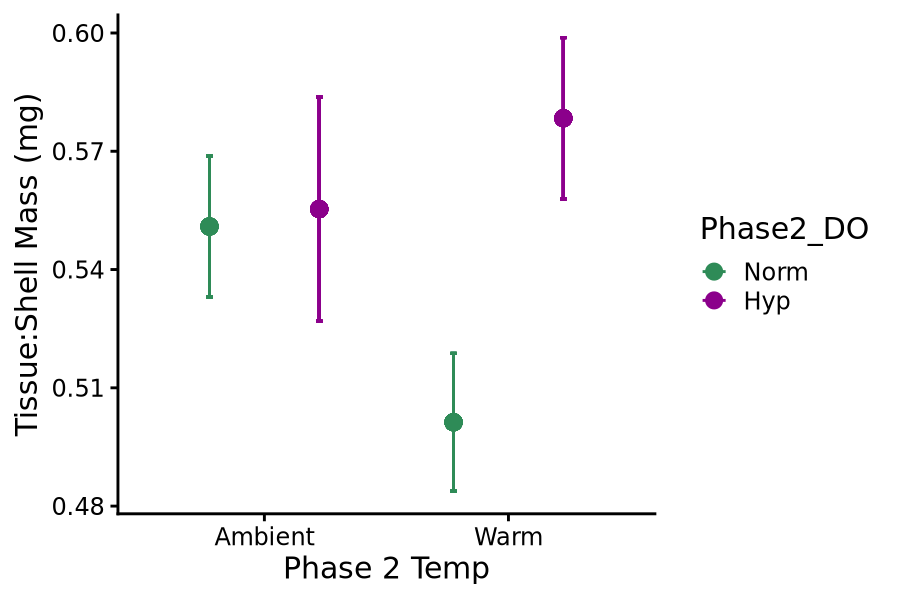

In [31]:
pre_summary_stats_t <- p2.mass %>%
  group_by(Phase2_DO, Phase2_temp) %>%
  mutate(
    mean_pre = mean(Ratio_tissue_shell_mg, na.rm = TRUE),
    se_pre = std.error(Ratio_tissue_shell_mg, na.rm = TRUE))

#reorder
pre_summary_stats_t$Phase2_DO <- factor(pre_summary_stats_t$Phase2_DO, levels = c("Norm", "Hyp"))
pre_summary_stats_t$Phase2_temp <- factor(pre_summary_stats_t$Phase2_temp, levels = c("Ambient", "Warm"))

#Tissue plot with mean and SD
ggplot(pre_summary_stats_t, aes(x = Phase2_temp, y = mean_pre, color = Phase2_DO)) +
  geom_point(size = 4, position = position_dodge(0.9)) + # Plot means as points
  geom_errorbar(aes(ymin = mean_pre - se_pre, ymax = mean_pre + se_pre), 
                width = 0.05, position = position_dodge(0.9)) + # Error bars for SD
  theme_classic(base_size = 18) +
  scale_color_manual(values = c("Hyp" = "darkmagenta", "Norm" = "seagreen")) +
  labs(x = "Phase 2 Temp", y = "Tissue:Shell Mass (mg)") 

so the significant interaction term comes into play when the phase 2 temperature is warm (no difference between DO when the temp is ambient)

T:S is a condition index
- higher T:S indicates more tissue than shell mass (investment in reproduction?)
- lower T:S indicates more shell than tissue mass (investment in defense?)

so warm/norm oysters have lower T:S than the other interactions, indicating that warm/norm has more shell than tissue than the other oysters (which is interesting? I feel like I would expect the both oyster (warm/hyp) to have less investment in reproduction)

## 4. conclusions:

similar to [growth](https://github.com/jgmcdonough/CE24_RNA-seq/blob/main/analysis/phenotype_data/growth/growth_treatments.ipynb), I do not see any significant differences in final mass between oysters that experienced different treatments/combination of treatments

all models pass the levenes test (no evidence for unequal variances between groups)

**How does this differ from what Sophie finds?**
